# CS6140 Machine Learning — Fall 2026
# HW3 Starter — Kernels, SVM, Kernel Ridge Regression, PCA, Kernel PCA

This notebook implements `HW3_26F.html`. Where a library offers the same functionality you'll run
it first as a sanity-check baseline, then implement the same thing from scratch and evaluate it
exactly the same way, so your two numbers should land right next to each other once everything is
filled in.

**Problems 1-4 (required):**
1. SVM: (A, B) via a library, several kernels: Spambase (binary), Digits/MNIST (multiclass);
   (C, D) from scratch: **Simplified SMO** (SVM note §5), validated on a linear kernel then run on
   RBF (the required non-linear case) — TwoSpirals
2. Kernel ridge regression from scratch (linear / RBF / polynomial kernels): WAVE, CRESCENT
3. PCA from scratch, feature-corruption narrative: polluted Spambase + logistic regression
4. Kernel PCA from scratch + linear classifier: TwoSpirals, ThreeCircles

**Problems 5-6 (THEORY, required):** each has a short setup (given code plus one blank) that produces
the plots you reason about, followed by a cell for your written answer.

**Problems 7-10 (optional, no credit):** t-SNE, PCA vs ICA vs Kernel PCA vs t-SNE, random Fourier
features, Dr. Lawler's patient similarity. They are skipped unless you set `RUN_OPTIONAL = True`
(cell right after Problem 6); their blanks are marked `### TODO_OPTIONAL ###` and are valid Python, so
skipping them never breaks the run. Optional Problems 11-20 have no starter code.

**Lecture notes** (notation and section numbers in this notebook follow them):
[SVM with Kernels](../lecture_notes/svm/SVM_claude_1001.pdf) ("SVM note"),
[Kernels and Kernelized Algorithms](../lecture_notes/kernels/KERNELS_claude_1001.pdf) ("Kernels note"),
[PCA and Feature Representations](../../5_features_dimensions/lecture_notes/PCA/PCA_claude_1001.pdf) ("PCA note").
In particular the Gaussian (RBF) kernel is written with a bandwidth &sigma;,
K(x,z) = exp(&minus;&Vert;x&minus;z&Vert;<sup>2</sup>/&sigma;<sup>2</sup>); scikit-learn calls the
same kernel with `gamma` = 1/&sigma;<sup>2</sup>, so every library call converts.

**How to work through this notebook.** Everything runs except the lines marked
`### TODO_STUDENT ###` — those have their code replaced with a `...` placeholder and a one-line
description of what to implement there (with the note section to look at). Read the surrounding
(working) code and the markdown above each section for context, then replace each stub with real
code. A cell with a stub in it will raise a `SyntaxError` until you fill it in — that's expected,
not a bug. In Problem 1's SMO, the L/H bounds come in two cases: the y_i != y_j case
is given as a worked example, and the y_i == y_j case (same idea, SVM note §5.2) is yours. Work top to bottom:
Problem 1's `linear_gram`/`rbf_gram`/`simplified_smo`/`predict_smo` are reused in both Part C
(linear) and Part D (RBF); Problem 3's `fit_eval_logreg` helper is reused by Problem 4. Every
hyperparameter or dimension choice (Problem 1's kernel grid, Problem 2's kernel/regularization,
Problem 4's `T`) is selected on a **validation** split and confirmed once on the held-out **test**
split — never pick a configuration by looking at test performance. Once a "library baseline"
cell's TODOs are filled in and run, the printed number is a target: your matching "from scratch"
implementation just below it should land on (or very near) the same value.

Datasets are read from the shared course `data/` folder (paths relative to this notebook's
directory, i.e. two levels up).

**Requirements.**
1. Fill in every `TODO_STUDENT` blank according to the algorithm steps covered in lecture and the
   linked notes, and make sure the notebook runs top to bottom without errors.
2. Understand the *whole* notebook — including the provided/given code, not just the blanks you
   filled in — well enough to explain any part of it during office hours.


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.decomposition import PCA, KernelPCA
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import LogisticRegression

DATA = "../data"
np.random.seed(42)


## Data loading

In [47]:
# ---- Spambase (binary classification): one file, split into train/val/test ----
# Validation is for model/hyperparameter selection (Problem 1's kernel grid); test is reserved
# for a single final reported number, never used to pick a configuration.
spam_raw = np.loadtxt(f"{DATA}/spambase/spambase.data", delimiter=",")
X_spam, y_spam = spam_raw[:, :-1], spam_raw[:, -1]          # y in {0,1}

X_train_spam, X_temp_spam, y_train_spam, y_temp_spam = train_test_split(
    X_spam, y_spam, test_size=0.4, random_state=42, stratify=y_spam)
X_val_spam, X_test_spam, y_val_spam, y_test_spam = train_test_split(
    X_temp_spam, y_temp_spam, test_size=0.5, random_state=42, stratify=y_temp_spam)

spam_scaler = StandardScaler().fit(X_train_spam)
X_train_spam = spam_scaler.transform(X_train_spam)
X_val_spam = spam_scaler.transform(X_val_spam)
X_test_spam = spam_scaler.transform(X_test_spam)

print("Spambase train:", X_train_spam.shape, " val:", X_val_spam.shape, " test:", X_test_spam.shape)


Spambase train: (2760, 57)  val: (920, 57)  test: (921, 57)


In [48]:
# ---- MNIST/Digits (Haar features): pre-extracted 200-dim features, subsampled like HW1 ----
X_train_digits_full = np.loadtxt(f"{DATA}/mnist_haar_bingyu/training_image.txt", delimiter=",")
y_train_digits_full = np.loadtxt(f"{DATA}/mnist_haar_bingyu/training_label.txt", delimiter=",")
X_test_digits_full = np.loadtxt(f"{DATA}/mnist_haar_bingyu/testing_image.txt", delimiter=",")
y_test_digits_full = np.loadtxt(f"{DATA}/mnist_haar_bingyu/testing_label.txt", delimiter=",")

n_train_digits, n_test_digits = 3000, 1000
rng = np.random.RandomState(0)
train_idx = rng.choice(len(X_train_digits_full), size=n_train_digits, replace=False)
test_idx = rng.choice(len(X_test_digits_full), size=n_test_digits, replace=False)

X_train_digits = X_train_digits_full[train_idx]
y_train_digits = y_train_digits_full[train_idx]
X_test_digits = X_test_digits_full[test_idx]
y_test_digits = y_test_digits_full[test_idx]

digits_scaler = StandardScaler().fit(X_train_digits)
X_train_digits = digits_scaler.transform(X_train_digits)
X_test_digits = digits_scaler.transform(X_test_digits)

print("Digits (Problem 1, Part B) train:", X_train_digits.shape, " test:", X_test_digits.shape)


Digits (Problem 1, Part B) train: (3000, 200)  test: (1000, 200)


In [49]:
# ---- WAVE and CRESCENT: 1-D input / 1-D output regression toy sets, one file each ----
# Same train/val/test convention as Spambase: val picks Problem 2's kernel/hyperparameters,
# test is reported once for the chosen configuration.
def load_1d_regression(name, val_size=0.2, test_size=0.2, seed=42):
    x = np.loadtxt(f"{DATA}/{name}X.txt").reshape(-1, 1)
    y = np.loadtxt(f"{DATA}/{name}Y.txt")
    x_train, x_temp, y_train, y_temp = train_test_split(
        x, y, test_size=val_size + test_size, random_state=seed)
    x_val, x_test, y_val, y_test = train_test_split(
        x_temp, y_temp, test_size=test_size / (val_size + test_size), random_state=seed)
    return x_train, x_val, x_test, y_train, y_val, y_test

X_train_wave, X_val_wave, X_test_wave, y_train_wave, y_val_wave, y_test_wave = load_1d_regression("wave")
X_train_crescent, X_val_crescent, X_test_crescent, y_train_crescent, y_val_crescent, y_test_crescent = load_1d_regression("crescent")

print("WAVE train:", X_train_wave.shape, " val:", X_val_wave.shape, " test:", X_test_wave.shape)
print("CRESCENT train:", X_train_crescent.shape, " val:", X_val_crescent.shape, " test:", X_test_crescent.shape)


WAVE train: (300, 1)  val: (100, 1)  test: (100, 1)
CRESCENT train: (300, 1)  val: (100, 1)  test: (100, 1)


In [50]:
# ---- Polluted Spambase (original features + junk/duplicated ones), already train/test split ----
X_train_pol = np.loadtxt(f"{DATA}/spam_polluted/train_feature.txt")
y_train_pol = np.loadtxt(f"{DATA}/spam_polluted/train_label.txt")
X_test_pol = np.loadtxt(f"{DATA}/spam_polluted/test_feature.txt")
y_test_pol = np.loadtxt(f"{DATA}/spam_polluted/test_label.txt")

pol_scaler = StandardScaler().fit(X_train_pol)
X_train_pol_s = pol_scaler.transform(X_train_pol)
X_test_pol_s = pol_scaler.transform(X_test_pol)

print("Polluted Spambase train:", X_train_pol.shape, " test:", X_test_pol.shape)


Polluted Spambase train: (4140, 1057)  test: (461, 1057)


In [51]:
# ---- TwoSpirals (binary, label in {-1,+1}) / ThreeCircles: 2-D points ----
# ThreeCircles is NOT binary despite the shared file format -- it's a balanced 3-class dataset,
# label in {-1, 0, +1} (333/333/334 points), so its chance level is ~33%, not ~50%.
# Same train/val/test convention as the other datasets: val is for Problem 4's T selection.
two_spirals = np.loadtxt(f"{DATA}/TwoSpirals/twoSpirals.txt")
three_circles = np.loadtxt(f"{DATA}/TwoSpirals/threecircles.txt", delimiter=",")

X_train_spirals, X_temp_spirals, y_train_spirals, y_temp_spirals = train_test_split(
    two_spirals[:, :2], two_spirals[:, 2], test_size=0.4, random_state=42, stratify=two_spirals[:, 2])
X_val_spirals, X_test_spirals, y_val_spirals, y_test_spirals = train_test_split(
    X_temp_spirals, y_temp_spirals, test_size=0.5, random_state=42, stratify=y_temp_spirals)

X_train_circles, X_temp_circles, y_train_circles, y_temp_circles = train_test_split(
    three_circles[:, :2], three_circles[:, 2], test_size=0.4, random_state=42, stratify=three_circles[:, 2])
X_val_circles, X_test_circles, y_val_circles, y_test_circles = train_test_split(
    X_temp_circles, y_temp_circles, test_size=0.5, random_state=42, stratify=y_temp_circles)

print("TwoSpirals (2 classes) train:", X_train_spirals.shape, " val:", X_val_spirals.shape, " test:", X_test_spirals.shape)
print("ThreeCircles (3 classes) train:", X_train_circles.shape, " val:", X_val_circles.shape, " test:", X_test_circles.shape)


TwoSpirals (2 classes) train: (600, 2)  val: (200, 2)  test: (200, 2)
ThreeCircles (3 classes) train: (600, 2)  val: (200, 2)  test: (200, 2)


---
## Problem 1 — SVM: library (Parts A–B), then from scratch with Simplified SMO (Parts C–D)

### Part A — Spambase (binary)
Try linear, polynomial, and RBF kernels; a small grid for each kernel's own hyperparameter
(SVM note §4.3 "Choosing the Kernel and C", §7 Implementation Notes; the kernels themselves are in
Kernels note §4). Configurations are compared on the **validation** set; the test set is reported
only once, for the configurations finally chosen, so it never influences which hyperparameters get
picked. The RBF grid is in &sigma; (sklearn's `gamma` = 1/&sigma;<sup>2</sup>).


In [52]:
svm_grid_results = []
for kernel, param_grid in [
    ("linear", [{"C": c} for c in [0.1, 1.0, 10.0]]),
    # sklearn's poly kernel is (gamma * x.z + coef0)^degree, here with its default gamma="scale"
    ("poly", [{"C": 1.0, "degree": d, "coef0": c0} for d in [2, 3] for c0 in [0.0, 1.0]]),
    ("rbf", [{"C": 1.0, "sigma": s} for s in [3.0, 4.5, 10.0, 30.0]]),
]:
    for params in param_grid:
        sk_params = {k: v for k, v in params.items() if k != "sigma"}
        if "sigma" in params:
            sk_params["gamma"] = 1 / params["sigma"]**2  # sklearn's gamma = 1/sigma^2
        clf = SVC(kernel=kernel, **sk_params).fit(X_train_spam, y_train_spam)  ### TODO_STUDENT ### fit an SVC with this kernel and hyperparameters as the library SVM baseline
        acc = clf.score(X_val_spam, y_val_spam)
        svm_grid_results.append((kernel, params, acc, clf.support_.shape[0]))
        print(f"kernel={kernel:<7} params={params}  val acc={acc:.4f}  #SV={clf.support_.shape[0]}")

best_kernel, best_params, best_val_acc, _ = max(svm_grid_results, key=lambda r: r[2])
print(f"\nBest on validation: kernel={best_kernel}, params={best_params}, val acc={best_val_acc:.4f}")


kernel=linear  params={'C': 0.1}  val acc=0.9261  #SV=657
kernel=linear  params={'C': 1.0}  val acc=0.9250  #SV=575
kernel=linear  params={'C': 10.0}  val acc=0.9228  #SV=554
kernel=poly    params={'C': 1.0, 'degree': 2, 'coef0': 0.0}  val acc=0.8402  #SV=1466
kernel=poly    params={'C': 1.0, 'degree': 2, 'coef0': 1.0}  val acc=0.9293  #SV=663
kernel=poly    params={'C': 1.0, 'degree': 3, 'coef0': 0.0}  val acc=0.7761  #SV=1636
kernel=poly    params={'C': 1.0, 'degree': 3, 'coef0': 1.0}  val acc=0.9239  #SV=612
kernel=rbf     params={'C': 1.0, 'sigma': 3.0}  val acc=0.8815  #SV=1524
kernel=rbf     params={'C': 1.0, 'sigma': 4.5}  val acc=0.9087  #SV=1108
kernel=rbf     params={'C': 1.0, 'sigma': 10.0}  val acc=0.9207  #SV=824
kernel=rbf     params={'C': 1.0, 'sigma': 30.0}  val acc=0.8978  #SV=1182

Best on validation: kernel=poly, params={'C': 1.0, 'degree': 2, 'coef0': 1.0}, val acc=0.9293


**Best linear and RBF configurations on Spambase** (selected on validation, confirmed once on test). The from-scratch SMO of Parts C–D runs on a different dataset, TwoSpirals — see Part C for why.

In [53]:
best_linear = max((r for r in svm_grid_results if r[0] == "linear"), key=lambda r: r[2])
_, best_linear_params, best_linear_val_acc, best_linear_nsv = best_linear
BEST_LINEAR_C = best_linear_params["C"]

linear_baseline = SVC(kernel="linear", C=BEST_LINEAR_C).fit(X_train_spam, y_train_spam)  ### TODO_STUDENT ### fit a linear-kernel SVC baseline at the best C found above
print(f"Library linear-SVM baseline (selected on validation): C={BEST_LINEAR_C}")
print(f"  train acc={linear_baseline.score(X_train_spam, y_train_spam):.4f}  "
      f"val acc={linear_baseline.score(X_val_spam, y_val_spam):.4f}  "
      f"test acc={linear_baseline.score(X_test_spam, y_test_spam):.4f}  #SV={linear_baseline.support_.shape[0]}")

best_rbf = max((r for r in svm_grid_results if r[0] == "rbf"), key=lambda r: r[2])
_, best_rbf_params, best_rbf_val_acc, best_rbf_nsv = best_rbf
BEST_SIGMA = best_rbf_params["sigma"]
BEST_C = best_rbf_params["C"]

rbf_baseline = SVC(kernel="rbf", C=BEST_C, gamma=1/BEST_SIGMA**2).fit(X_train_spam, y_train_spam)  ### TODO_STUDENT ### fit an RBF-kernel SVC baseline at the best (C, sigma) found above (sklearn's gamma = 1/sigma^2)
print(f"\nLibrary RBF-SVM baseline (selected on validation): C={BEST_C}, sigma={BEST_SIGMA}")
print(f"  train acc={rbf_baseline.score(X_train_spam, y_train_spam):.4f}  "
      f"val acc={rbf_baseline.score(X_val_spam, y_val_spam):.4f}  "
      f"test acc={rbf_baseline.score(X_test_spam, y_test_spam):.4f}  #SV={rbf_baseline.support_.shape[0]}")


Library linear-SVM baseline (selected on validation): C=0.1
  train acc=0.9344  val acc=0.9261  test acc=0.9175  #SV=657

Library RBF-SVM baseline (selected on validation): C=1.0, sigma=10.0
  train acc=0.9449  val acc=0.9207  test acc=0.9207  #SV=824


### Part B — Digits/MNIST (multiclass, required)\n\n`sklearn.svm.SVC` handles multiclass natively (one-vs-one internally, 45 binary classifiers for 10 classes). We also build an explicit one-vs-rest wrapper (10 classifiers) with `OneVsRestClassifier` and compare the two schemes (SVM note §6 Multiclass SVMs). RBF kernel with &sigma; = 10 (`gamma` = 0.01).

In [54]:
DIGITS_SIGMA = 10.0
svc_multiclass = SVC(kernel="rbf", C=1.0, gamma=1 / DIGITS_SIGMA**2, decision_function_shape="ovo")  # sklearn's gamma = 1/sigma^2
svc_multiclass = svc_multiclass.fit(X_train_digits, y_train_digits)  ### TODO_STUDENT ### fit sklearn's native multiclass SVC (one-vs-one internally) on Digits
acc_ovo = svc_multiclass.score(X_test_digits, y_test_digits)
print(f"Native multiclass SVC (one-vs-one, 45 classifiers): test acc={acc_ovo:.4f}")

ovr = OneVsRestClassifier(SVC(kernel="rbf", C=1.0, gamma=1 / DIGITS_SIGMA**2))
ovr = ovr.fit(X_train_digits, y_train_digits)  ### TODO_STUDENT ### fit an explicit one-vs-rest multiclass wrapper on Digits
acc_ovr = ovr.score(X_test_digits, y_test_digits)
print(f"Explicit one-vs-rest wrapper (10 classifiers):      test acc={acc_ovr:.4f}")


Native multiclass SVC (one-vs-one, 45 classifiers): test acc=0.9210
Explicit one-vs-rest wrapper (10 classifiers):      test acc=0.9300


### Parts C–D — SVM from scratch: Simplified SMO

Implements the **Simplified SMO algorithm** of the SVM note (§5.2 "One SMO Step", §5.3 the
"Simplified SMO" algorithm box; based on the CS229 Simplified SMO notes, but written in Platt's
sign convention &eta; = K<sub>ii</sub> + K<sub>jj</sub> &minus; 2K<sub>ij</sub> &ge; 0 — see the
remark at the end of §5.2, and don't mix the two conventions): iterate over all
&alpha;<sub>i</sub>, pick a random &alpha;<sub>j</sub> whenever &alpha;<sub>i</sub> violates the
KKT conditions, jointly optimize the pair, stop after `max_passes` sweeps with no change (capped by
`max_sweeps`, see below and SVM note §7). This is deliberately *not* full Platt SMO (no error
cache, no entire-set/non-bound alternation, no second-choice heuristic; SVM Advanced note §6) — that
fuller version is one of the optional extensions below.

The solver itself never looks at raw features, only a precomputed kernel (Gram) matrix `K` — so
the exact same function works for any kernel; only the Gram matrix passed in changes.

**Dataset choice: TwoSpirals, not Spambase.** On Spambase a linear kernel already does about as
well as RBF (Part A) — kernels aren't buying anything there, so it's a poor demonstration of
*why* the kernel trick matters. **TwoSpirals** (reused from Problem 4) makes the point directly:
it is not linearly separable by construction, so a linear-kernel SVM is stuck near chance while an
RBF-kernel SVM — the exact same solver, just a different Gram matrix — solves it almost perfectly.

**Part C — linear kernel, a correctness check (not expected to classify well here).** With a linear
kernel the dual solution gives back an explicit primal weight vector,
`w = &sum;&alpha;<sub>i</sub>y<sub>i</sub>x<sub>i</sub>`, which should match
`SVC(kernel='linear').coef_` *reasonably well* at the same C (SVM note §7, "Checks"): the same
**direction** (cosine similarity &asymp; 1) and similar accuracy. An exact match of the
**magnitude** as well requires full convergence, which the 300-sweep cap may not reach on this
non-separable data, so expect a clearly non-zero relative L2 difference (its size depends on the
random pair choices; ~0.1-0.2 is normal here) and a slightly different b. A second check is the
**set of support vectors** (points with &alpha;<sub>i</sub> &gt; 0), which should largely coincide
with `SVC`'s `support_` (overlap / Jaccard index printed below). The poor accuracy itself is the
kernel's fault, not the solver's.

**Part D — RBF kernel, the required non-linear case** — identical solver code, RBF Gram matrix
(&sigma; = 1) substituted in, benchmarked against a library RBF-SVM on the same data.


In [55]:
def linear_gram(A, B):
    return A @ B.T  # given -- the linear kernel is just the dot product, nothing to derive


def rbf_gram(A, B, sigma):
    sq_a = np.sum(A**2, axis=1)[:, None]
    sq_b = np.sum(B**2, axis=1)[None, :]
    sq_dist = sq_a + sq_b - 2 * A @ B.T
    np.maximum(sq_dist, 0, out=sq_dist)
    return np.exp(-sq_dist / sigma**2)  ### TODO_STUDENT ### implement the Gaussian kernel exp(-||x-z||^2 / sigma^2) given the squared distances [Kernels note §4.3]


def simplified_smo(K, y, C=1.0, tol=1e-3, max_passes=5, max_sweeps=300, verbose=False):
    """Simplified SMO (SVM note §5.3 algorithm box; one pair update = §5.2 "One SMO Step"),
    given a precomputed kernel matrix K. Kernel-agnostic: swap in a linear or RBF Gram matrix,
    nothing else changes. Uses Platt's sign convention eta = K_ii + K_jj - 2 K_ij >= 0.

    The stopping rule (`max_passes` consecutive sweeps with no change) assumes near-separable
    data and isn't guaranteed to trigger on noisy, non-separable real data -- on this dataset the
    linear kernel in particular keeps making small updates near the margin for a very long time
    (still adjusting alphas at sweep 300 on TwoSpirals). `max_sweeps` is a hard cap so runtime
    stays bounded regardless (SVM note §7). Empirically the RBF kernel's *accuracy* already
    matches the library's well before the cap; the linear kernel's accuracy, weight-vector
    *direction* (cosine similarity) and support-vector set also match closely, but its weight
    vector has not fully converged in magnitude by sweep 300 -- see Part C's printed relative
    difference.
    """
    m = K.shape[0]
    alpha = np.zeros(m)
    b = 0.0
    passes = 0

    def f(i):
        return np.sum(alpha * y * K[:, i]) + b  ### TODO_STUDENT ### implement the SVM decision function f(x_i) = sum_k alpha_k y_k K(x_k, x_i) + b [SVM note §5.2]

    sweep = 0
    while passes < max_passes and sweep < max_sweeps:
        sweep += 1
        num_changed = 0
        for i in range(m):
            Ei = f(i) - y[i]  # given -- the error E_i = f(x_i) - y_i
            if (y[i] * Ei < -tol and alpha[i] < C) or (y[i] * Ei > tol and alpha[i] > 0):  ### TODO_STUDENT ### check whether alpha_i violates the KKT conditions [SVM note §5.3, first paragraph]
                j = i
                while j == i:
                    j = np.random.randint(0, m)  # given -- mechanical index bookkeeping, not part of the KKT/SMO math
                Ej = f(j) - y[j]  # given -- same error formula as E_i, for index j
                alpha_i_old, alpha_j_old = alpha[i], alpha[j]

                if y[i] != y[j]:
                    # given, worked example -- the y_i == y_j case below is the mirror-image derivation to fill in
                    L = max(0.0, alpha[j] - alpha[i])
                    H = min(C, C + alpha[j] - alpha[i])
                else:
                    L = max(0.0, alpha[i] + alpha[j] - C)  ### TODO_STUDENT ### compute the lower bound L when y_i == y_j [SVM note §5.2, step 1] -- mirrors the y_i != y_j case above
                    H = min(C, alpha[i] + alpha[j])  ### TODO_STUDENT ### compute the upper bound H when y_i == y_j [SVM note §5.2, step 1] -- mirrors the y_i != y_j case above
                if L == H:
                    continue

                eta = K[i, i] + K[j, j] - 2 * K[i, j]  ### TODO_STUDENT ### compute eta = K_ii + K_jj - 2 K_ij, the curvature along the constraint line (Platt's convention, eta >= 0) [SVM note §5.2]
                if eta <= 0:
                    continue

                alpha[j] = alpha[j] + y[j] * (Ei - Ej) / eta  ### TODO_STUDENT ### compute the unclipped update for alpha_j [SVM note §5.2, step 2]
                alpha[j] = min(H, max(L, alpha[j]))  # given -- mechanical clamp into [L, H] once L, H are known [SVM note §5.2, step 3]
                if abs(alpha[j] - alpha_j_old) < 1e-5:
                    alpha[j] = alpha_j_old  # given -- revert: no meaningful update, so undo it rather than
                    continue                #          leave alpha_j drifted with no compensating alpha_i change

                alpha[i] = alpha[i] + y[i] * y[j] * (alpha_j_old - alpha[j])  ### TODO_STUDENT ### update alpha_i to offset the change in alpha_j [SVM note §5.2, step 4]

                # given -- the two thresholds b1, b2 and the three-case rule for b [SVM note §5.2, step 5]
                b1 = (b - Ei - y[i] * (alpha[i] - alpha_i_old) * K[i, i]
                        - y[j] * (alpha[j] - alpha_j_old) * K[i, j])
                b2 = (b - Ej - y[i] * (alpha[i] - alpha_i_old) * K[i, j]
                        - y[j] * (alpha[j] - alpha_j_old) * K[j, j])
                if 0 < alpha[i] < C:
                    b = b1
                elif 0 < alpha[j] < C:
                    b = b2
                else:
                    b = (b1 + b2) / 2.0
                num_changed += 1
        if verbose and sweep % 20 == 0:
            print(f"  sweep {sweep}: alphas changed this sweep = {num_changed}")
        passes = passes + 1 if num_changed == 0 else 0

    sv = alpha > 1e-6
    return alpha, b, sv


def predict_smo(X_train, y_train, alpha, b, gram_fn, X_query):
    sv = alpha > 1e-6
    K = gram_fn(X_train[sv], X_query)
    scores = (alpha[sv] * y_train[sv]) @ K + b  # given -- same decision-function formula as f(i) above, restricted to support vectors
    return np.where(scores >= 0, 1.0, -1.0)  # given -- threshold into +-1 (>=0, not np.sign, so an exact-zero score is +1 per convention, not the undefined 0)


#### Part C — linear kernel: validate against `SVC(kernel='linear')` (weight vector, support vectors, accuracy)

In [56]:
import time

SMO_C = 1.0
linear_baseline_spirals = SVC(kernel="linear", C=SMO_C)  ### TODO_STUDENT ### fit a linear-kernel SVC baseline on TwoSpirals
linear_baseline_spirals = linear_baseline_spirals.fit(X_train_spirals, y_train_spirals)  ### TODO_STUDENT ### fit the linear-kernel SVC baseline on TwoSpirals

K_lin_train = linear_gram(X_train_spirals, X_train_spirals)
t0 = time.time()
alpha_lin, b_lin, sv_lin = simplified_smo(
    K_lin_train, y_train_spirals, C=SMO_C, tol=1e-3, max_passes=5, verbose=True)
t_lin = time.time() - t0

w_scratch = (alpha_lin * y_train_spirals) @ X_train_spirals  ### TODO_STUDENT ### recover the primal weight vector w = sum(alpha_i y_i x_i) from the dual solution (only valid for a linear kernel) [SVM note §2.3]
w_lib = linear_baseline_spirals.coef_.ravel()

w_rel_diff = np.linalg.norm(w_scratch - w_lib) / np.linalg.norm(w_lib)
cos_sim = np.dot(w_scratch, w_lib) / (np.linalg.norm(w_scratch) * np.linalg.norm(w_lib))

# given -- second check (SVM note §7): support-vector sets, ours (alpha_i > 0) vs SVC's support_
sv_lib = np.zeros(len(y_train_spirals), dtype=bool)
sv_lib[linear_baseline_spirals.support_] = True
sv_overlap = np.sum(sv_lin & sv_lib)
sv_jaccard = sv_overlap / np.sum(sv_lin | sv_lib)

pred_train_lin = predict_smo(X_train_spirals, y_train_spirals, alpha_lin, b_lin, linear_gram, X_train_spirals)
pred_test_lin = predict_smo(X_train_spirals, y_train_spirals, alpha_lin, b_lin, linear_gram, X_test_spirals)
acc_train_lin = np.mean(pred_train_lin == y_train_spirals)
acc_test_lin = np.mean(pred_test_lin == y_test_spirals)

print(f"\n[Simplified SMO, linear kernel, TwoSpirals]  C={SMO_C}  #SV={sv_lin.sum()}  train time={t_lin:.1f}s")
print(f"  cosine(w_scratch, w_lib) = {cos_sim:.4f}   ||w_scratch - w_lib|| / ||w_lib|| = {w_rel_diff:.4f}"
      f"  (magnitude needs full convergence; the sweep cap may stop short)")
print(f"  b_scratch={b_lin:.4f}  b_lib={linear_baseline_spirals.intercept_[0]:.4f}")
print(f"  support vectors: ours={sv_lin.sum()}  SVC={sv_lib.sum()}  overlap={sv_overlap}  Jaccard={sv_jaccard:.3f}")
print(f"  train acc={acc_train_lin:.4f}  test acc={acc_test_lin:.4f}  (near chance, as expected -- "
      f"the kernel, not the optimizer, is the bottleneck here)")
print(f"\n[Library SVC linear baseline, TwoSpirals]  C={SMO_C}  "
      f"train acc={linear_baseline_spirals.score(X_train_spirals, y_train_spirals):.4f}  "
      f"test acc={linear_baseline_spirals.score(X_test_spirals, y_test_spirals):.4f}")


  sweep 20: alphas changed this sweep = 436
  sweep 40: alphas changed this sweep = 209
  sweep 60: alphas changed this sweep = 167
  sweep 80: alphas changed this sweep = 115
  sweep 100: alphas changed this sweep = 94
  sweep 120: alphas changed this sweep = 85
  sweep 140: alphas changed this sweep = 65
  sweep 160: alphas changed this sweep = 59
  sweep 180: alphas changed this sweep = 63
  sweep 200: alphas changed this sweep = 61
  sweep 220: alphas changed this sweep = 51
  sweep 240: alphas changed this sweep = 55
  sweep 260: alphas changed this sweep = 35
  sweep 280: alphas changed this sweep = 28
  sweep 300: alphas changed this sweep = 27

[Simplified SMO, linear kernel, TwoSpirals]  C=1.0  #SV=525  train time=1.4s
  cosine(w_scratch, w_lib) = 0.9946   ||w_scratch - w_lib|| / ||w_lib|| = 0.1626  (magnitude needs full convergence; the sweep cap may stop short)
  b_scratch=0.0081  b_lib=0.0224
  support vectors: ours=525  SVC=441  overlap=441  Jaccard=0.840
  train acc=0.651

#### Part D — RBF kernel: same solver, RBF Gram matrix, the required non-linear case

In [57]:
SMO_SIGMA = 1.0
rbf_baseline_spirals = SVC(kernel="rbf", C=SMO_C, gamma=1 / SMO_SIGMA**2).fit(X_train_spirals, y_train_spirals)  ### TODO_STUDENT ### fit an RBF-kernel SVC baseline on TwoSpirals (sklearn's gamma = 1/sigma^2)  ### TODO_STUDENT ### fit the RBF-kernel SVC baseline on TwoSpirals

K_rbf_train = rbf_gram(X_train_spirals, X_train_spirals, SMO_SIGMA)
t0 = time.time()
alpha_rbf, b_rbf, sv_rbf = simplified_smo(
    K_rbf_train, y_train_spirals, C=SMO_C, tol=1e-3, max_passes=5, verbose=True)
t_rbf = time.time() - t0

rbf_gram_fixed = lambda A, B: rbf_gram(A, B, SMO_SIGMA)
pred_train_rbf = predict_smo(X_train_spirals, y_train_spirals, alpha_rbf, b_rbf, rbf_gram_fixed, X_train_spirals)
pred_test_rbf = predict_smo(X_train_spirals, y_train_spirals, alpha_rbf, b_rbf, rbf_gram_fixed, X_test_spirals)
acc_train_rbf = np.mean(pred_train_rbf == y_train_spirals)
acc_test_rbf = np.mean(pred_test_rbf == y_test_spirals)

print(f"\n[Simplified SMO, RBF kernel, TwoSpirals]  C={SMO_C}, sigma={SMO_SIGMA}  #SV={sv_rbf.sum()}  "
      f"train time={t_rbf:.1f}s")
print(f"  train acc={acc_train_rbf:.4f}  test acc={acc_test_rbf:.4f}")

print(f"\n[Library SVC RBF baseline, TwoSpirals]  C={SMO_C}, sigma={SMO_SIGMA} (gamma={1 / SMO_SIGMA**2:g})  "
      f"#SV={len(rbf_baseline_spirals.support_)}  "
      f"train acc={rbf_baseline_spirals.score(X_train_spirals, y_train_spirals):.4f}  "
      f"test acc={rbf_baseline_spirals.score(X_test_spirals, y_test_spirals):.4f}")


  sweep 20: alphas changed this sweep = 154
  sweep 40: alphas changed this sweep = 111
  sweep 60: alphas changed this sweep = 81
  sweep 80: alphas changed this sweep = 60
  sweep 100: alphas changed this sweep = 59
  sweep 120: alphas changed this sweep = 46
  sweep 140: alphas changed this sweep = 31
  sweep 160: alphas changed this sweep = 20
  sweep 180: alphas changed this sweep = 17
  sweep 200: alphas changed this sweep = 12
  sweep 220: alphas changed this sweep = 5
  sweep 240: alphas changed this sweep = 4
  sweep 260: alphas changed this sweep = 2
  sweep 280: alphas changed this sweep = 12
  sweep 300: alphas changed this sweep = 3

[Simplified SMO, RBF kernel, TwoSpirals]  C=1.0, sigma=1.0  #SV=249  train time=1.0s
  train acc=1.0000  test acc=1.0000

[Library SVC RBF baseline, TwoSpirals]  C=1.0, sigma=1.0 (gamma=1)  #SV=247  train acc=1.0000  test acc=1.0000


**The point:** identical solver, identical data, one Gram matrix swapped in for another — linear stays near chance, RBF solves it almost perfectly.

**Optional extensions (not implemented here):** running this SMO on the Digits dataset via a
multiclass wrapper (optional Problem 11); SMO with the *full* Platt heuristics (error cache,
entire-set/non-bound alternation, second-choice pair selection — optional Problem 12, SVM Advanced note §6
and the [Platt SMO paper](../materials/platt-smo-book.pdf)); solving the same dual with a library
QP solver (optional Problem 13, SVM Advanced note §5).


---
## Problem 2 — Kernel Ridge Regression from scratch

Kernels note §8 (kernel ridge regression), kernels from §4.1–4.3: linear x z<sup>T</sup>,
polynomial (x z<sup>T</sup> + c)<sup>p</sup>, Gaussian exp(&minus;&Vert;x&minus;z&Vert;<sup>2</sup>/&sigma;<sup>2</sup>).
Kernel ridge regression has no intercept, so we **center the labels** (§8, "The intercept"):
with ȳ the training mean,

&alpha; = (K + &lambda;I)<sup>&minus;1</sup>(y &minus; ȳ),&nbsp;&nbsp;&nbsp;
h(z) = ȳ + &sum;<sub>i</sub>&alpha;<sub>i</sub>K(x<sub>i</sub>, z).

The wrapper (`fit`/`predict`, solving the linear system with `np.linalg.solve`, never an explicit
inverse) is from scratch (Kernels note §13). Hyperparameters (&lambda;, and &sigma; or the degree p)
are selected on the **validation** set; test MSE is reported once, for the chosen configuration,
and separately checked against sklearn's `KernelRidge` (`alpha`=&lambda;, `gamma`=1/&sigma;<sup>2</sup>)
at the same (kernel, hyperparameters), with the labels centered the same way, as a library
baseline.


In [58]:
class KernelRidgeRegression:
    def __init__(self, kernel="rbf", lam=1.0, sigma=1.0, c=1.0, p=3):
        self.kernel = kernel
        self.lam = lam      # ridge penalty lambda
        self.sigma = sigma  # Gaussian bandwidth
        self.c = c          # polynomial kernel offset
        self.p = p          # polynomial kernel degree

    def _kernel_matrix(self, A, B):
        if self.kernel == "linear":
            return A @ B.T  # given -- the linear kernel is just the dot product, nothing to derive
        elif self.kernel == "rbf":
            sq_dist = np.sum(A**2, 1)[:, None] + np.sum(B**2, 1)[None, :] - 2 * A @ B.T
            return np.exp(-sq_dist / self.sigma**2 )  ### TODO_STUDENT ### implement the Gaussian kernel exp(-||x-z||^2 / sigma^2) given the squared distances [Kernels note §4.3]
        elif self.kernel == "poly":
            return (A @ B.T + self.c)**self.p  ### TODO_STUDENT ### implement the polynomial kernel (x z^T + c)^p [Kernels note §4.2]
        raise ValueError(self.kernel)

    def fit(self, X, y):
        self.X_train_ = X
        self.y_mean = y.mean()  # given -- KRR has no intercept, so fit the centered labels y - y_mean [Kernels note §8, "The intercept"]
        K = self._kernel_matrix(X, X)
        n = K.shape[0]
        # alpha = (K + lam*I)^{-1} (y - y_mean)   [Kernels note §8]
        self.alpha = np.linalg.solve(K + self.lam * np.eye(n), y - self.y_mean)  ### TODO_STUDENT ### solve the kernel ridge dual system (K + lam*I) alpha = y - y_mean (np.linalg.solve, not an inverse)
        return self

    def predict(self, X):
        K_test = self._kernel_matrix(X, self.X_train_)  # [n_query, n_train]
        # h(z) = y_mean + sum_i alpha_i K(x_i, z)   [Kernels note §8]
        return self.y_mean + K_test @ self.alpha  ### TODO_STUDENT ### predict y_mean plus the weighted sum of kernel evaluations against the training points


In [59]:
def tune_and_fit(X_train, y_train, X_val, y_val, kernel):
    grids = {
        "linear": [{"lam": lam} for lam in [0.001, 0.01, 0.1, 1.0]],
        "rbf": [{"lam": lam, "sigma": s}
                for lam in [0.001, 0.01, 0.1, 1.0, 10.0] for s in [0.1, 0.15, 0.2, 0.3, 0.45, 0.7, 1.0, 1.4]],
        "poly": [{"lam": lam, "c": 1.0, "p": p}
                 for lam in [0.001, 0.01, 0.1, 1.0, 10.0] for p in [2, 3, 5]],
    }
    best = None
    for params in grids[kernel]:
        model = KernelRidgeRegression(kernel=kernel, **params).fit(X_train, y_train)
        mse_val = mean_squared_error(y_val, model.predict(X_val))
        if best is None or mse_val < best[1]:
            best = (params, mse_val, model)
    return best  # (params, val_mse, fitted_model)


kr_data = {
    "WAVE": (X_train_wave, X_val_wave, X_test_wave, y_train_wave, y_val_wave, y_test_wave),
    "CRESCENT": (X_train_crescent, X_val_crescent, X_test_crescent, y_train_crescent, y_val_crescent, y_test_crescent),
}
kr_results = {}
for name, (Xtr, Xv, Xte, ytr, yv, yte) in kr_data.items():
    print(f"=== {name} ===")
    kr_results[name] = {}
    for kernel in ["linear", "rbf", "poly"]:
        params, mse_val, model = tune_and_fit(Xtr, ytr, Xv, yv, kernel)
        mse_train = mean_squared_error(ytr, model.predict(Xtr))
        mse_test = mean_squared_error(yte, model.predict(Xte))
        kr_results[name][kernel] = (params, mse_train, mse_val, mse_test, model)
        print(f"  {kernel:<7} params={params} (selected on val)  "
              f"train MSE={mse_train:.4f}  val MSE={mse_val:.4f}  test MSE={mse_test:.4f}")


=== WAVE ===
  linear  params={'lam': 1.0} (selected on val)  train MSE=0.4096  val MSE=0.4949  test MSE=0.3919
  rbf     params={'lam': 0.01, 'sigma': 1.0} (selected on val)  train MSE=0.0125  val MSE=0.0158  test MSE=0.0129
  poly    params={'lam': 0.01, 'c': 1.0, 'p': 5} (selected on val)  train MSE=0.0134  val MSE=0.0165  test MSE=0.0137
=== CRESCENT ===
  linear  params={'lam': 1.0} (selected on val)  train MSE=0.0985  val MSE=0.0946  test MSE=0.1051
  rbf     params={'lam': 1.0, 'sigma': 0.3} (selected on val)  train MSE=0.0104  val MSE=0.0100  test MSE=0.0080
  poly    params={'lam': 1.0, 'c': 1.0, 'p': 2} (selected on val)  train MSE=0.0117  val MSE=0.0112  test MSE=0.0099


**Library baseline: `sklearn.kernel_ridge.KernelRidge`**, at each dataset's validation-selected (kernel, hyperparameters), labels centered the same way, to confirm the from-scratch dual solve. sklearn's names: `alpha`=&lambda;, RBF `gamma`=1/&sigma;<sup>2</sup>, poly (`gamma`&middot;x z<sup>T</sup> + `coef0`)<sup>`degree`</sup> with `gamma`=1, `coef0`=c, `degree`=p.

In [60]:
def sklearn_krr(kernel, params):
    # given -- translate the note's (lam, sigma, c, p) into sklearn's KernelRidge arguments
    if kernel == "linear":
        return KernelRidge(alpha=params["lam"], kernel="linear")
    if kernel == "rbf":
        return KernelRidge(alpha=params["lam"], kernel="rbf", gamma=1 / params["sigma"]**2)  # sklearn's gamma = 1/sigma^2
    return KernelRidge(alpha=params["lam"], kernel="poly", degree=params["p"], coef0=params["c"], gamma=1)


print("sklearn KernelRidge baseline, at each dataset's validation-selected (kernel, hyperparameters):")
for name, (Xtr, Xv, Xte, ytr, yv, yte) in kr_data.items():
    best_kernel = min(kr_results[name], key=lambda k: kr_results[name][k][2])
    params, _, _, mse_test_scratch, model = kr_results[name][best_kernel]
    y_mean = ytr.mean()  # given -- same label centering as the from-scratch model
    sk_model = sklearn_krr(best_kernel, params).fit(Xtr, ytr - y_mean)  ### TODO_STUDENT ### fit sklearn's KernelRidge on the centered labels as a library baseline at the same (kernel, hyperparameters)
    sk_pred = y_mean + sk_model.predict(Xte)
    mse_test_sklearn = mean_squared_error(yte, sk_pred)
    max_abs_diff = np.max(np.abs(sk_pred - model.predict(Xte)))
    print(f"  {name}: kernel={best_kernel} params={params}  scratch test MSE={mse_test_scratch:.4f}  "
          f"sklearn test MSE={mse_test_sklearn:.4f}  max|scratch-sklearn| on test predictions={max_abs_diff:.2e}")


sklearn KernelRidge baseline, at each dataset's validation-selected (kernel, hyperparameters):
  WAVE: kernel=rbf params={'lam': 0.01, 'sigma': 1.0}  scratch test MSE=0.0129  sklearn test MSE=0.0129  max|scratch-sklearn| on test predictions=8.53e-14
  CRESCENT: kernel=rbf params={'lam': 1.0, 'sigma': 0.3}  scratch test MSE=0.0080  sklearn test MSE=0.0080  max|scratch-sklearn| on test predictions=5.22e-15


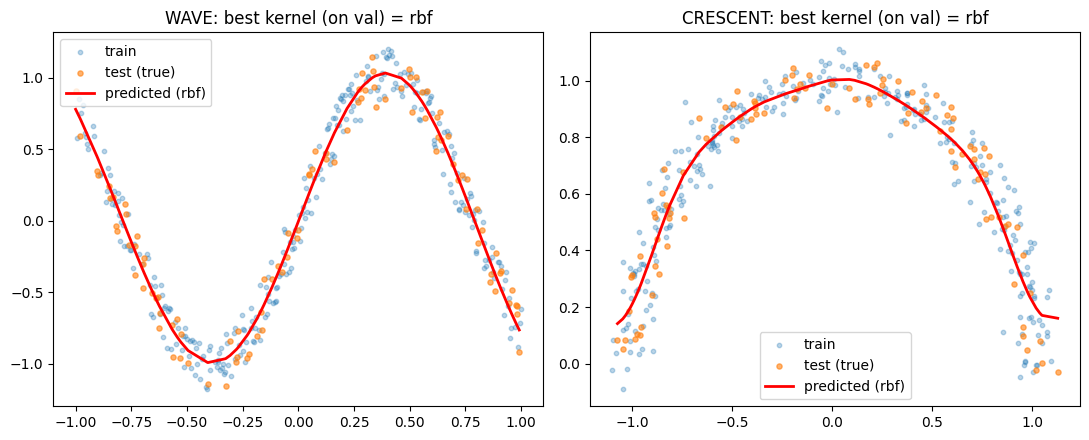

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["WAVE", "CRESCENT"]):
    Xtr, Xv, Xte, ytr, yv, yte = kr_data[name]
    order = np.argsort(Xte[:, 0])
    ax.scatter(Xtr[:, 0], ytr, s=10, alpha=0.3, label="train")
    ax.scatter(Xte[:, 0], yte, s=14, alpha=0.6, label="test (true)")
    best_kernel = min(kr_results[name], key=lambda k: kr_results[name][k][2])
    model = kr_results[name][best_kernel][4]
    ax.plot(Xte[order, 0], model.predict(Xte)[order], "r-", lw=2,
            label=f"predicted ({best_kernel})")
    ax.set_title(f"{name}: best kernel (on val) = {best_kernel}")
    ax.legend()
plt.tight_layout()
plt.show()


### Which kernel does better, and why?

Answer in your own words, citing *your* numbers and plots — there is no answer key here:

- **Look at the WAVE plot.** How many times does the curve change direction on [&minus;1, 1]? What
  does that mean for a linear fit, and what is the smallest polynomial degree p that could follow it?
- **Local vs. global kernels** (Kernels note §4). An RBF fit is a sum of Gaussian bumps around the
  training points; a polynomial fit is one degree-p polynomial over the whole input range. What
  shapes can each of them take? Which kernel and which hyperparameters did validation pick on each
  dataset, and does that match the shape of the data?
- **Bandwidth.** Compare the &sigma; that validation selected for WAVE with the spacing of WAVE's
  bumps. What would you expect to see with a much smaller &sigma;, or a much larger one?
- **CRESCENT vs. WAVE.** How does CRESCENT's shape differ? Is the gap between the linear kernel and
  the non-linear ones larger or smaller there than on WAVE, and why?


---
## Problem 3 — PCA from scratch (feature corruption & rescue)

PCA note §6 (the algorithm: &mu;, centered X&#771;, top-t directions C<sub>t</sub>,
Z = (X &minus; &mu;)C<sub>t</sub>), §8 (computing it with the SVD of the centered data), §9
(Implementation Notes). Downstream classifier: `sklearn.linear_model.LogisticRegression` (per the
assignment note, reusing HW2's classifier choice, not from-scratch here — the from-scratch piece in
this problem is PCA). Scaler and PCA are fit on the training split only.


In [62]:
def fit_eval_logreg(X_train, y_train, X_test, y_test, max_iter=2000):
    clf = LogisticRegression(max_iter=max_iter).fit(X_train, y_train)  ### TODO_STUDENT ### fit sklearn's LogisticRegression as the downstream classifier (library baseline, reused across (A)/(B)/(C) and Problem 4)
    return accuracy_score(y_train, clf.predict(X_train)), accuracy_score(y_test, clf.predict(X_test))


# (0) control: same classifier on the ORIGINAL, unpolluted 57-feature Spambase (loaded in setup)
# -- this is the "before" number the (A) vs (B)/(C) comparison below is a drop/rescue relative to.
acc_train_clean, acc_test_clean = fit_eval_logreg(X_train_spam, y_train_spam, X_test_spam, y_test_spam)
print(f"(0) Unpolluted Spambase, 57 dims (control): "
      f"train acc={acc_train_clean:.4f}  test acc={acc_test_clean:.4f}")

# (A) raw polluted features
acc_train_raw, acc_test_raw = fit_eval_logreg(X_train_pol_s, y_train_pol, X_test_pol_s, y_test_pol)
print(f"(A) Raw polluted features ({X_train_pol_s.shape[1]} dims): "
      f"train acc={acc_train_raw:.4f}  test acc={acc_test_raw:.4f}")


(0) Unpolluted Spambase, 57 dims (control): train acc=0.9272  test acc=0.9175
(A) Raw polluted features (1057 dims): train acc=0.9920  test acc=0.8568


In [63]:
# (B) library PCA -> ~100 features (fit on train only, applied to test)
# svd_solver="full" (not the "auto" default, which picks randomized/approximate SVD for a
# matrix this shape): keeps this an apples-to-apples comparison with the from-scratch SVD
# in (C), which is also exact.
N_COMPONENTS = 100
lib_pca = PCA(n_components=N_COMPONENTS, svd_solver="full").fit(X_train_pol_s)  ### TODO_STUDENT ### fit sklearn's PCA as the library baseline, reducing to N_COMPONENTS dimensions
X_train_pca_lib = lib_pca.transform(X_train_pol_s)
X_test_pca_lib = lib_pca.transform(X_test_pol_s)

acc_train_lib, acc_test_lib = fit_eval_logreg(X_train_pca_lib, y_train_pol, X_test_pca_lib, y_test_pol)
print(f"(B) sklearn PCA -> {N_COMPONENTS} dims: "
      f"train acc={acc_train_lib:.4f}  test acc={acc_test_lib:.4f}")
print(f"    explained variance ratio (cumulative): {lib_pca.explained_variance_ratio_.sum():.4f}")


(B) sklearn PCA -> 100 dims: train acc=0.9261  test acc=0.9393
    explained variance ratio (cumulative): 0.9350


In [64]:
# (C) own PCA  [PCA note §6 algorithm box; §8 for the SVD route]
class MyPCA:
    def __init__(self, t):
        self.t = t  # number of principal directions kept

    def fit(self, X):
        self.mu = X.mean(axis=0)  # given -- mean of the training rows
        X_tilde = X - self.mu
        # SVD of the centered data, X_tilde = U S V^T: the columns of V (rows of Vt) are the
        # principal directions e_j, and lambda_j = s_j^2 / N  [PCA note §8]. Numerically nicer
        # than forming and eigendecomposing the D x D covariance matrix, same directions.
        U, S, Vt = np.linalg.svd(X_tilde, full_matrices=False)  ### TODO_STUDENT ### compute the SVD of the centered data to get the principal directions
        self.C_t = Vt[: self.t].T  ### TODO_STUDENT ### keep the top t directions as the COLUMNS of C_t (D x t)
        self.lambdas = S[: self.t] ** 2 / X.shape[0]  # given -- the note's 1/N convention (sklearn's explained_variance_ uses 1/(N-1))
        return self

    def transform(self, X):
        # Z = (X - mu) C_t, with the STORED training mu and C_t  [PCA note §6]
        return (X - self.mu) @ self.C_t  ### TODO_STUDENT ### project the centered data onto the stored principal directions


my_pca = MyPCA(t=N_COMPONENTS).fit(X_train_pol_s)
X_train_pca_mine = my_pca.transform(X_train_pol_s)
X_test_pca_mine = my_pca.transform(X_test_pol_s)

acc_train_mine, acc_test_mine = fit_eval_logreg(X_train_pca_mine, y_train_pol, X_test_pca_mine, y_test_pol)
print(f"(C) own PCA -> {N_COMPONENTS} dims: "
      f"train acc={acc_train_mine:.4f}  test acc={acc_test_mine:.4f}")

# sanity checks against the library (PCA note §9): same eigenvalues (up to the 1/N vs 1/(N-1)
# factor) and the same projections up to the sign of each component
N_train = X_train_pol_s.shape[0]
eig_rel_diff = np.max(np.abs(my_pca.lambdas * N_train / (N_train - 1) - lib_pca.explained_variance_)
                      / lib_pca.explained_variance_)
per_component_corr = [abs(np.corrcoef(X_train_pca_lib[:, k], X_train_pca_mine[:, k])[0, 1])
                       for k in range(N_COMPONENTS)]
print(f"    max relative eigenvalue difference vs library: {eig_rel_diff:.2e}")
print(f"    |correlation| between library- and own-PCA components: "
      f"min={min(per_component_corr):.4f}  mean={np.mean(per_component_corr):.4f}")


(C) own PCA -> 100 dims: train acc=0.9266  test acc=0.9393
    max relative eigenvalue difference vs library: 1.77e-16
    |correlation| between library- and own-PCA components: min=1.0000  mean=1.0000


In [65]:
print(f"{'method':<28}{'train acc':>12}{'test acc':>12}")
print(f"{'(0) unpolluted (control)':<28}{acc_train_clean:>12.4f}{acc_test_clean:>12.4f}")
print(f"{'(A) raw polluted':<28}{acc_train_raw:>12.4f}{acc_test_raw:>12.4f}")
print(f"{'(B) library PCA':<28}{acc_train_lib:>12.4f}{acc_test_lib:>12.4f}")
print(f"{'(C) own PCA':<28}{acc_train_mine:>12.4f}{acc_test_mine:>12.4f}")


method                         train acc    test acc
(0) unpolluted (control)          0.9272      0.9175
(A) raw polluted                  0.9920      0.8568
(B) library PCA                   0.9261      0.9393
(C) own PCA                       0.9266      0.9393


**Looking inside the data** (given code): eigenvalue spectra / variance explained of the clean vs. polluted training features (PCA note §5.4), and how strongly each column is correlated with some other column. Use these numbers when you explain the table above.

clean Spambase   : D=57  top-5 variance fractions=[0.117 0.058 0.038 0.028 0.027]
    directions needed for 50/90/95/99% of the variance: 16/43/48/54
    median over columns of max|corr| with another column: 0.268
polluted Spambase: D=1057  top-5 variance fractions=[0.596 0.176 0.07  0.038 0.003]
    directions needed for 50/90/95/99% of the variance: 1/18/220/751
    median over columns of max|corr| with another column: 0.961


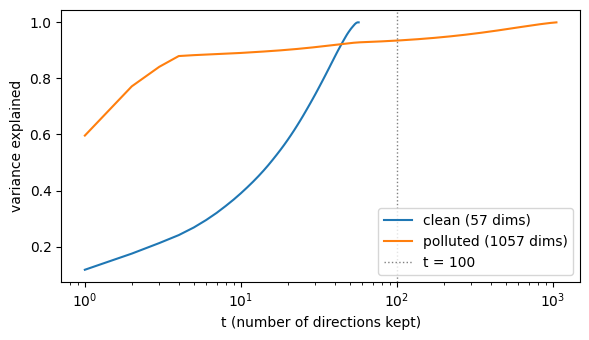

In [66]:
def spectrum_summary(X_std, label):
    lambdas = np.linalg.svd(X_std - X_std.mean(axis=0), compute_uv=False) ** 2 / X_std.shape[0]
    frac = np.cumsum(lambdas) / lambdas.sum()
    t_needed = {q: int(np.searchsorted(frac, q) + 1) for q in [0.5, 0.9, 0.95, 0.99]}
    corr = np.corrcoef(X_std.T)
    np.fill_diagonal(corr, 0)
    max_corr = np.nanmax(np.abs(corr), axis=1)  # each column's strongest correlation with another column
    print(f"{label}: D={X_std.shape[1]}  top-5 variance fractions={np.round(lambdas[:5] / lambdas.sum(), 3)}")
    print(f"    directions needed for 50/90/95/99% of the variance: "
          f"{t_needed[0.5]}/{t_needed[0.9]}/{t_needed[0.95]}/{t_needed[0.99]}")
    print(f"    median over columns of max|corr| with another column: {np.median(max_corr):.3f}")
    return lambdas

lambdas_clean = spectrum_summary(X_train_spam, "clean Spambase   ")
lambdas_pol = spectrum_summary(X_train_pol_s, "polluted Spambase")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(lambdas_clean) + 1), np.cumsum(lambdas_clean) / lambdas_clean.sum(), label="clean (57 dims)")
ax.plot(np.arange(1, len(lambdas_pol) + 1), np.cumsum(lambdas_pol) / lambdas_pol.sum(), label=f"polluted ({X_train_pol_s.shape[1]} dims)")
ax.axvline(N_COMPONENTS, color="gray", ls=":", lw=1, label=f"t = {N_COMPONENTS}")
ax.set_xscale("log")
ax.set_xlabel("t (number of directions kept)")
ax.set_ylabel("variance explained")
ax.legend()
plt.tight_layout()
plt.show()


### Why does PCA help here?

Answer in your own words, citing *your* numbers — there is no answer key here:

- **The drop.** Compare (A)'s train and test accuracy with the (0) control. What does the gap
  between train and test on the raw polluted features tell you?
- **The spectra.** Using the "looking inside the data" cell: how do the eigenvalue spectra /
  variance explained of the polluted and the clean features differ? How many directions carry most
  of the variance, how much is spread over the rest, and how strongly correlated are the columns?
- **Duplicated columns.** Recall what PCA does with a duplicated column (PCA note §7, the
  redundant-feature example). What does that suggest about how the polluted features were made, and
  about what PCA keeps and discards?
- **Before vs. after.** How many inputs does the classifier see before and after PCA, and how
  correlated are they? Why would that matter for how well a linear classifier generalizes?
- **Your PCA vs. the library.** Do the eigenvalues and components agree (up to sign)? Why doesn't
  a sign flip change the classifier's accuracy?


**The drop:** On the raw polluted features, train accuracy is 0.992 but test accuracy is only 0.857, a gap of about 13 points. On the clean 57-feature data the two are close (0.927 train, 0.918 test). The gap tells us the model is overfitting. With 1,057 features, many of them junk, the model has enough freedom to memorize the training emails, including random patterns in the junk features, instead of learning the general pattern. Those random patterns don't repeat in new emails, so test accuracy drops below even the clean model's.

**The spectra:** The two spectra look very different. On clean data the variance is spread out: the biggest direction holds only 11.7%, and it takes 43 of the 57 directions to reach 90%. On polluted data the variance is packed into a few directions: the first one alone holds 59.6%, and 18 directions already reach 90%. After that the curve goes almost flat, and it takes 220 directions to reach 95% and 751 to reach 99%, so the remaining variance is spread thinly over hundreds of directions. The columns are also much more correlated: the median column's strongest correlation with another column is 0.961, compared with 0.268 on clean data.

**Duplicated columns:** In the PCA note's redundant-feature example, copying a column doesn't add a new direction. The copy lies along the same direction as the original and just adds more variance to it. That fits what we see here. A median correlation of 0.961 means almost every column has a near-copy, so the polluted features were most likely made by duplicating (or nearly duplicating) the original features, plus some added noise. The duplicates pile variance onto a few directions, which is why one direction holds 60%. The noise shows up as the long flat tail of tiny directions. PCA keeps the few large directions, which carry the original information, and drops the tail, which is mostly noise.

**Before vs. after:** Before PCA, the classifier gets 1,057 inputs that are highly correlated with each other, so it has 1,057 weights to fit. When inputs are near-copies, their weights can trade off against each other in almost any way, which makes it easy to fit noise in the training set. After PCA, it gets 100 inputs that are uncorrelated by construction, so there are far fewer weights and no redundancy between them. That makes memorizing much harder, and the train/test gap closes: 0.926 train and 0.939 test, compared with 0.992 and 0.857 before.

**Your PCA vs. the library:** They agree. The largest relative difference in eigenvalues is 1.77e-16, which is just floating-point rounding, and every one of the 100 components has |correlation| = 1.0000 with sklearn's. Test accuracy is identical (0.9393). Some components can come out with the opposite sign, because a direction and its negative describe the same line. A sign flip doesn't change accuracy: logistic regression just learns the opposite weight for that feature, since w·(−x) = (−w)·x, so the predictions stay the same.

---
## Problem 4 — Kernel PCA + linear classifier

Kernels note §11 (Kernel PCA): §11.2 (PCA with dot products only, the normalization
&beta; = u/&radic;&nu;), §11.4 (centering inside K, the algorithm box), §13 (Implementation Notes).

**Note:** TwoSpirals is binary (`{-1,+1}`, chance &asymp; 50%). ThreeCircles, despite the shared
2-D-points file format, is a balanced **3-class** dataset (`{-1,0,+1}`, chance &asymp; 33%) — see
the comment in the TwoSpirals/ThreeCircles loading cell at the top. Keep that in mind when reading
the raw-classifier accuracies below.

### (A) A linear classifier fails on the raw 2-D data


In [67]:
for name, (Xtr, Xte, ytr, yte) in {
    "TwoSpirals": (X_train_spirals, X_test_spirals, y_train_spirals, y_test_spirals),
    "ThreeCircles": (X_train_circles, X_test_circles, y_train_circles, y_test_circles),
}.items():
    acc_train, acc_test = fit_eval_logreg(Xtr, ytr, Xte, yte)
    n_classes = len(np.unique(ytr))
    print(f"{name} ({n_classes} classes, chance {'~50%' if n_classes == 2 else '~33%'}): "
          f"raw-2D logistic regression  train acc={acc_train:.4f}  test acc={acc_test:.4f}")


TwoSpirals (2 classes, chance ~50%): raw-2D logistic regression  train acc=0.6650  test acc=0.6700
ThreeCircles (3 classes, chance ~33%): raw-2D logistic regression  train acc=0.3817  test acc=0.3500


### (B) Kernel PCA from scratch (Gaussian kernel)

Follow the algorithm box of Kernels note §11.4, with U the N&times;N matrix of 1/N's and U' the
M&times;N matrix of 1/N's:

1. **Fit:** training kernel K (N&times;N); center it, K&#772; = K &minus; UK &minus; KU + UKU.
2. Eigendecompose K&#772;; sort by decreasing eigenvalue &nu;<sub>1</sub> &ge; &nu;<sub>2</sub> &ge; &hellip;
   (`np.linalg.eigh` returns them in *increasing* order); keep the top T with &nu; &gt; 0;
   &beta;<sub>k</sub> = u<sub>k</sub>/&radic;&nu;<sub>k</sub>, stacked as the columns of B.
3. **Transform:** K<sub>test</sub> (M&times;N, kernel against the *training* points), centered with
   the training statistics, K&#772;<sub>test</sub> = K<sub>test</sub> &minus; U'K &minus; K<sub>test</sub>U + U'KU;
   coordinates K&#772;<sub>test</sub>B (for the training points themselves this gives K&#772;B).


In [68]:
class MyKernelPCA:
    def __init__(self, n_components, sigma=1.0):
        self.n_components = n_components  # T
        self.sigma = sigma                # Gaussian bandwidth

    @staticmethod
    def _rbf(A, B, sigma):
        sq_dist = np.sum(A**2, 1)[:, None] + np.sum(B**2, 1)[None, :] - 2 * A @ B.T
        return np.exp(-sq_dist / sigma**2)

    def fit(self, X):
        self.X_train_ = X
        N = X.shape[0]
        K = self._rbf(X, X, self.sigma)  # given -- just calling the kernel already implemented above on the training data
        U = np.full((N, N), 1.0 / N)
        # K_bar = K - U K - K U + U K U   [Kernels note §11.4]
        K_bar = K - U @ K - K @ U + U @ K @ U  ### TODO_STUDENT ### center the kernel matrix in feature space

        nus, us = np.linalg.eigh(K_bar)  ### TODO_STUDENT ### eigendecompose the centered kernel matrix (eigenvalues nu, unit eigenvectors u)
        order = np.argsort(nus)[::-1][: self.n_components]  # given -- eigh's order is increasing: sort descending, keep the top T
        nus, us = nus[order], us[:, order]
        keep = nus > 1e-10  # given -- drop eigenvalues <= 0 (numerical noise) [Kernels note §13]
        nus, us = nus[keep], us[:, keep]

        self.nus_ = nus
        # beta_k = u_k / sqrt(nu_k), so that ||e_k|| = 1   [Kernels note §11.2]
        self.betas_ = us / np.sqrt(nus)  ### TODO_STUDENT ### normalize each eigenvector by the square root of its eigenvalue (columns of B)
        self.K_train_ = K
        return self

    def transform(self, X):
        K = self.K_train_                          # [N, N]
        N = K.shape[0]
        K_test = self._rbf(X, self.X_train_, self.sigma)  # [M, N], kernel against the TRAINING points
        U = np.full((N, N), 1.0 / N)
        U_prime = np.full((K_test.shape[0], N), 1.0 / N)  # U' (M x N)
        # K_test_bar = K_test - U' K - K_test U + U' K U   [Kernels note §11.4]
        K_test_bar = K_test - U_prime @ K - K_test @ U + U_prime @ K @ U  ### TODO_STUDENT ### center the test kernel with the TRAINING statistics
        return K_test_bar @ self.betas_  ### TODO_STUDENT ### coordinates = K_test_bar B, a single matrix product


`T` is chosen on the **validation** set (smallest `T` reaching a "good performance" bar of 90%
validation accuracy, falling back to the largest `T` tried if none clear it), then confirmed once
on the held-out test set — same protocol as Problems 1 and 2. Gaussian kernel with &sigma; = 1.


In [69]:
SIGMA_KPCA = 1.0
T_VALUES = [2, 5, 10, 20, 50]
GOOD_ACC_THRESHOLD = 0.9

kpca_data = {
    "TwoSpirals": (X_train_spirals, X_val_spirals, X_test_spirals, y_train_spirals, y_val_spirals, y_test_spirals),
    "ThreeCircles": (X_train_circles, X_val_circles, X_test_circles, y_train_circles, y_val_circles, y_test_circles),
}
kpca_results = {}
chosen_T = {}
for name, (Xtr, Xv, Xte, ytr, yv, yte) in kpca_data.items():
    print(f"=== {name} ===")
    kpca_results[name] = []
    for T in T_VALUES:
        kpca = MyKernelPCA(n_components=T, sigma=SIGMA_KPCA).fit(Xtr)
        Xtr_kpca, Xv_kpca = kpca.transform(Xtr), kpca.transform(Xv)
        acc_train, acc_val = fit_eval_logreg(Xtr_kpca, ytr, Xv_kpca, yv)
        kpca_results[name].append((T, acc_train, acc_val))
        print(f"  T={T:<3} train acc={acc_train:.4f}  val acc={acc_val:.4f}")
    good_Ts = [T for T, _, acc_val in kpca_results[name] if acc_val >= GOOD_ACC_THRESHOLD]
    chosen_T[name] = good_Ts[0] if good_Ts else T_VALUES[-1]
    print(f"  -> smallest T with val acc >= {GOOD_ACC_THRESHOLD:.0%}: T={chosen_T[name]}")

print("\nFinal held-out test confirmation, at each dataset's chosen T:")
test_acc_at_chosen_T = {}
kpca_chosen = {}
for name, (Xtr, Xv, Xte, ytr, yv, yte) in kpca_data.items():
    T = chosen_T[name]
    kpca = MyKernelPCA(n_components=T, sigma=SIGMA_KPCA).fit(Xtr)
    kpca_chosen[name] = kpca
    _, acc_test = fit_eval_logreg(kpca.transform(Xtr), ytr, kpca.transform(Xte), yte)
    test_acc_at_chosen_T[name] = acc_test
    print(f"  {name}: T={T}  test acc={acc_test:.4f}")


=== TwoSpirals ===
  T=2   train acc=0.5850  val acc=0.5800
  T=5   train acc=0.7117  val acc=0.6750
  T=10  train acc=0.8200  val acc=0.8000
  T=20  train acc=0.9017  val acc=0.9000
  T=50  train acc=0.9950  val acc=0.9950
  -> smallest T with val acc >= 90%: T=20
=== ThreeCircles ===
  T=2   train acc=0.6033  val acc=0.5600
  T=5   train acc=1.0000  val acc=1.0000
  T=10  train acc=1.0000  val acc=1.0000
  T=20  train acc=1.0000  val acc=1.0000
  T=50  train acc=1.0000  val acc=1.0000
  -> smallest T with val acc >= 90%: T=5

Final held-out test confirmation, at each dataset's chosen T:
  TwoSpirals: T=20  test acc=0.8550
  ThreeCircles: T=5  test acc=1.0000


**Library baseline: `sklearn.decomposition.KernelPCA`** (`gamma` = 1/&sigma;<sup>2</sup>), at each dataset's chosen `T`. Its `transform` should match K&#772;<sub>test</sub>B up to the sign of each column (Kernels note §13).

In [70]:
print("sklearn KernelPCA baseline, at each dataset's chosen T:")
for name, (Xtr, Xv, Xte, ytr, yv, yte) in kpca_data.items():
    T = chosen_T[name]
    sk_kpca = KernelPCA(n_components=T, kernel='rbf', gamma=1/kpca_chosen[name].sigma**2).fit(Xtr)  ### TODO_STUDENT ### fit sklearn's KernelPCA as a library baseline at the chosen T (sklearn's gamma = 1/sigma^2)
    Xtr_sk, Xte_sk = sk_kpca.transform(Xtr), sk_kpca.transform(Xte)
    _, acc_test_sk = fit_eval_logreg(Xtr_sk, ytr, Xte_sk, yte)
    Xte_mine = kpca_chosen[name].transform(Xte)
    max_abs_diff = np.max(np.abs(np.abs(Xte_mine) - np.abs(Xte_sk)))  # given -- compare up to the sign of each column
    print(f"  {name}: T={T}  scratch test acc={test_acc_at_chosen_T[name]:.4f}  "
          f"sklearn KernelPCA -> logistic test acc={acc_test_sk:.4f}  "
          f"max | |scratch| - |sklearn| | on test coordinates={max_abs_diff:.2e}")


sklearn KernelPCA baseline, at each dataset's chosen T:
  TwoSpirals: T=20  scratch test acc=0.8550  sklearn KernelPCA -> logistic test acc=0.8550  max | |scratch| - |sklearn| | on test coordinates=1.36e-13
  ThreeCircles: T=5  scratch test acc=1.0000  sklearn KernelPCA -> logistic test acc=1.0000  max | |scratch| - |sklearn| | on test coordinates=3.28e-15


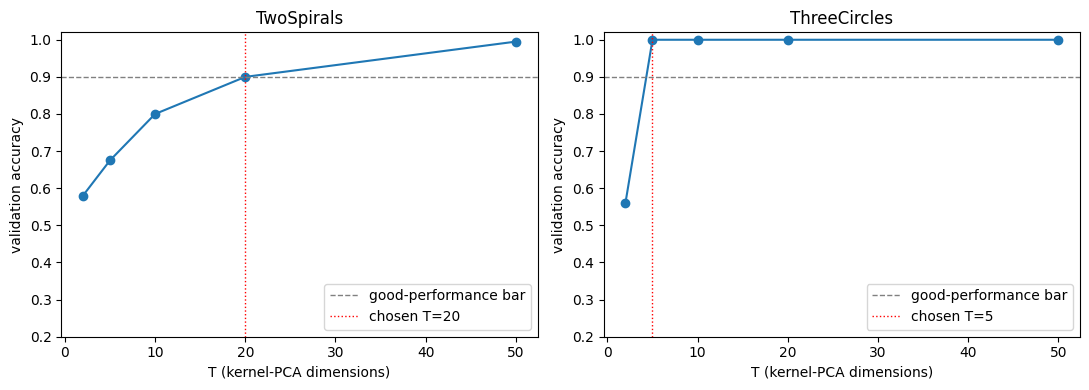

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["TwoSpirals", "ThreeCircles"]):
    Ts = [r[0] for r in kpca_results[name]]
    val_accs = [r[2] for r in kpca_results[name]]
    ax.plot(Ts, val_accs, "o-")
    ax.axhline(GOOD_ACC_THRESHOLD, color="gray", ls="--", lw=1, label="good-performance bar")
    ax.axvline(chosen_T[name], color="r", ls=":", lw=1, label=f"chosen T={chosen_T[name]}")
    ax.set_xlabel("T (kernel-PCA dimensions)")
    ax.set_ylabel("validation accuracy")
    ax.set_title(name)
    ax.set_ylim(0.2, 1.02)
    ax.legend()
plt.tight_layout()
plt.show()


In [72]:
print(f'How large must T be? (>= {GOOD_ACC_THRESHOLD:.0%} validation accuracy counts as "good")')
for name in ["TwoSpirals", "ThreeCircles"]:
    print(f"  {name}: smallest T reaching the bar = {chosen_T[name]}")


How large must T be? (>= 90% validation accuracy counts as "good")
  TwoSpirals: smallest T reaching the bar = 20
  ThreeCircles: smallest T reaching the bar = 5


---
## Problem 5 (THEORY) — Choosing the RBF Bandwidth in Kernel Ridge Regression

**Setup (given code + one blank).** Your Problem 2 `KernelRidgeRegression` on WAVE, Gaussian kernel,
&lambda; fixed at the value Problem 2 selected, sweeping the bandwidth &sigma; from far too small to far
too large (Kernels note §4.3 for what &sigma; does, §8 for the model). Look at the fits and at how
train and validation MSE move with &sigma;, then write your answer below.

sigma=0.005  train MSE=0.0000  val MSE=0.1575
sigma=0.01   train MSE=0.0012  val MSE=0.0584
sigma=0.02   train MSE=0.0053  val MSE=0.0259
sigma=0.05   train MSE=0.0095  val MSE=0.0162
sigma=0.1    train MSE=0.0112  val MSE=0.0168
sigma=0.2    train MSE=0.0119  val MSE=0.0164
sigma=0.45   train MSE=0.0123  val MSE=0.0161
sigma=1.0    train MSE=0.0125  val MSE=0.0158
sigma=2.0    train MSE=0.0353  val MSE=0.0336
sigma=5.0    train MSE=0.3710  val MSE=0.4564
sigma=10.0   train MSE=0.4077  val MSE=0.4981
(lambda = 0.01; Problem 2 selected sigma = 1.0)


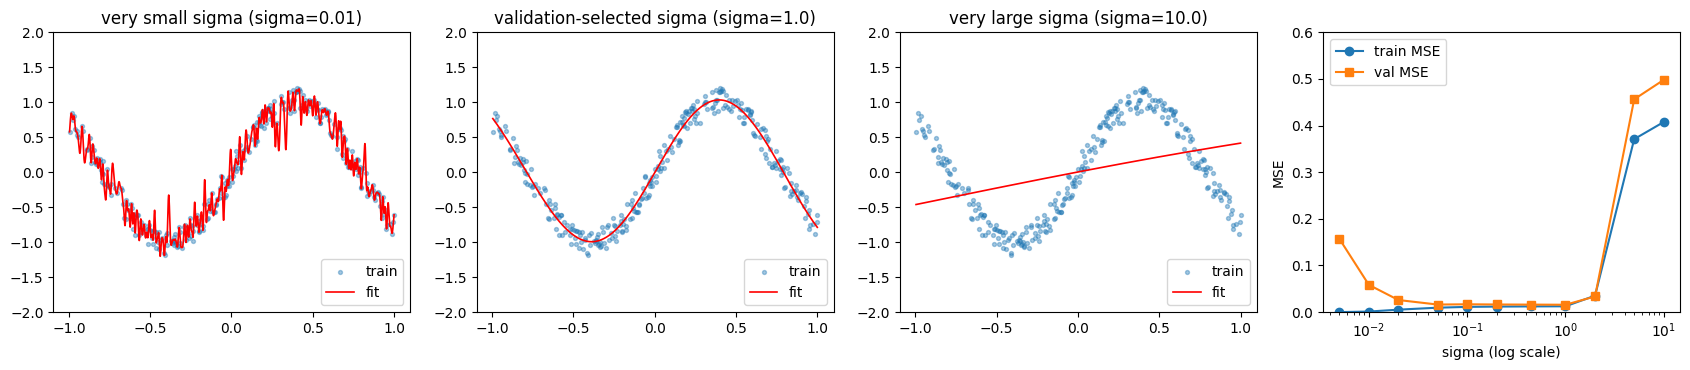

In [73]:
P5_LAM = kr_results["WAVE"]["rbf"][0]["lam"]
P5_SIGMA_SELECTED = kr_results["WAVE"]["rbf"][0]["sigma"]
p5_sigmas = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.45, 1.0, 2.0, 5.0, 10.0]
Xtr, Xv, Xte, ytr, yv, yte = kr_data["WAVE"]

p5_rows = []
for s in p5_sigmas:
    m = KernelRidgeRegression(kernel="rbf", lam=P5_LAM, sigma=s).fit(Xtr, ytr)
    mse_tr = mean_squared_error(ytr, m.predict(Xtr))
    mse_val = mean_squared_error(yv, m.predict(Xv))  ### TODO_STUDENT ### validation MSE of this fit -- the number you would use to choose sigma [Kernels note §4.3]
    p5_rows.append((s, mse_tr, mse_val))
    print(f"sigma={s:<6} train MSE={mse_tr:.4f}  val MSE={mse_val:.4f}")
print(f"(lambda = {P5_LAM}; Problem 2 selected sigma = {P5_SIGMA_SELECTED})")

x_grid = np.linspace(Xtr.min(), Xtr.max(), 1500).reshape(-1, 1)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, s, title in zip(axes[:3], [0.01, P5_SIGMA_SELECTED, 10.0],
                        ["very small sigma", "validation-selected sigma", "very large sigma"]):
    m = KernelRidgeRegression(kernel="rbf", lam=P5_LAM, sigma=s).fit(Xtr, ytr)
    ax.scatter(Xtr[:, 0], ytr, s=8, alpha=0.4, label="train")
    ax.plot(x_grid[:, 0], m.predict(x_grid), "r-", lw=1.2, label="fit")
    ax.set_title(f"{title} (sigma={s})")
    ax.set_ylim(-2, 2)
    ax.legend(loc="lower right")
axes[3].semilogx([r[0] for r in p5_rows], [r[1] for r in p5_rows], "o-", label="train MSE")
axes[3].semilogx([r[0] for r in p5_rows], [r[2] for r in p5_rows], "s-", label="val MSE")
axes[3].set_xlabel("sigma (log scale)")
axes[3].set_ylabel("MSE")
axes[3].set_ylim(0, 0.6)
axes[3].legend()
plt.tight_layout()
plt.show()


### Problem 5 — how to think about it

Answer in your own words, citing *your* plots and numbers:

- **What the model is.** Write the prediction h(z) as a sum over training points (Kernels note §8).
  What does one term look like as a function of z, and how wide is it?
- **Very small &sigma;.** Compare &sigma; with the typical gap between neighboring training x's. What does
  the kernel matrix K look like then (hint: off-diagonal entries), and what does that imply for
  &alpha; and for the fit at, and between, the training points?
- **Very large &sigma;.** What happens to K(x, z) for all pairs of points in [&minus;1, 1]? What kind of
  curves can a sum of such terms produce?
- **The MSE plot.** How do train and validation MSE move as &sigma; grows? Which of the two could you use
  to choose &sigma;, and why not the other one? Where else in this HW did you choose a hyperparameter
  the same way?

In [74]:
np.median(np.diff(np.sort(X_train_wave[:, 0])))

np.float64(0.004008016032064132)

**What the model is:** The prediction is h(z) = ȳ + Σᵢ αᵢ exp(−(z − xᵢ)²/σ²). Each term is a bell-shaped bump centered on one training point xᵢ, with height αᵢ and width about σ. The fitted curve is the sum of all these bumps, so σ controls how wide each one is.

**Very small σ:** The typical gap between neighboring training x's is about 0.004. When σ is about that size or smaller (σ = 0.005, 0.01), each bump only covers its own training point. The kernel matrix K has almost-zero off-diagonal entries, so K ≈ I and α ≈ (y − ȳ)/(1 + λ). Each bump just reaches up to its own point's label. That gives a near-perfect fit at the training points (train MSE = 0.0000 at σ = 0.005), but between them the curve has nothing to follow, so it jumps up and down from point to point. In the σ = 0.01 plot, the red curve is tracing the noise in the data, not the wave. This is overfitting, and validation MSE is high (0.158 at σ = 0.005).

**Very large σ:** All points are in [−1, 1], so the largest distance between any two of them is 2. At σ = 10, K(x, z) ≥ exp(−0.04) ≈ 0.96 for every pair, so every bump is almost flat and almost the same. Adding up nearly flat bumps can only give a very smooth curve, close to a straight line. The σ = 10 plot shows exactly that: a tilted line that misses the wave completely. Train MSE there is 0.41, about the same as the linear kernel in Problem 2. This is underfitting.

**The MSE plot:** Train MSE goes up steadily as σ grows, from 0.0000 to 0.41. Validation MSE is U-shaped: high at small σ (0.158), lowest and nearly flat between σ = 0.05 and σ = 1.0 (about 0.016), and high again at large σ (0.50). Train MSE can't be used to choose σ, because it always prefers the smallest σ, which is the one that memorizes the noise. Validation MSE measures performance on points the model hasn't seen, so it catches both overfitting and underfitting. The right way to pick σ is the minimum of validation MSE (or k-fold cross-validation if the data is small), which here gives σ = 1.0, the same σ Problem 2 selected. We chose hyperparameters the same way in Problem 1 (kernel and C on Spambase), Problem 2 (λ, σ, and p), and Problem 4 (T).

---
## Problem 6 (THEORY) — One-vs-Rest Ambiguity in Multiclass Regions

**Setup (given code + one blank).** A 2-D, 3-class toy set (three Gaussian blobs), so the regions can be
drawn. Three linear one-vs-rest SVMs, one per class (SVM note §6): at each point of a grid we count how
many of them say "yes, my class" (score &gt; 0). For comparison, the three one-vs-one SVMs and their
votes. Look at the maps, then write your answer below.

share of the plotted area where one-vs-rest says 'yes' 0 times: 2.6%, 2+ times: 28.8%
share of the plotted area with a 3-way tie in one-vs-one voting: 0.0%


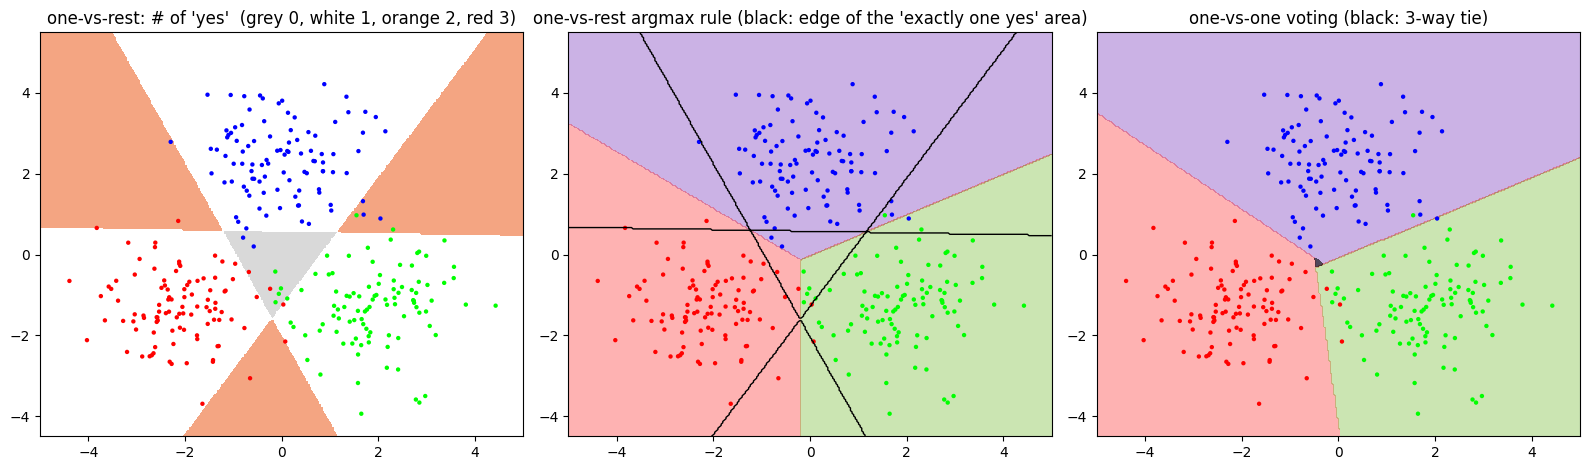

In [75]:
from sklearn.datasets import make_blobs

X6, y6 = make_blobs(n_samples=300, centers=[[0, 2.2], [-2, -1.2], [2, -1.2]], cluster_std=0.9,
                    random_state=0)
g1, g2 = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-4.5, 5.5, 300))
G = np.column_stack([g1.ravel(), g2.ravel()])

# one-vs-rest: classifier k answers "is it class k?"
ovr6 = [SVC(kernel="linear", C=1.0).fit(X6, np.where(y6 == k, 1, -1)) for k in range(3)]
scores6 = np.column_stack([m.decision_function(G) for m in ovr6])
n_yes = (scores6 > 0).sum(axis=1)  ### TODO_STUDENT ### at each grid point, count how many one-vs-rest classifiers say "yes" (score > 0) [SVM note §6]

# one-vs-one: classifier (a, b) is trained on classes a and b only, and votes for one of them
votes6 = np.zeros((len(G), 3))
for a, b in [(0, 1), (0, 2), (1, 2)]:
    mask = (y6 == a) | (y6 == b)
    m = SVC(kernel="linear", C=1.0).fit(X6[mask], np.where(y6[mask] == a, 1, -1))
    winner = np.where(m.decision_function(G) > 0, a, b)
    votes6[np.arange(len(G)), winner] += 1
ovo_tie = votes6.max(axis=1) == 1          # every class got exactly one vote

print(f"share of the plotted area where one-vs-rest says 'yes' 0 times: {np.mean(n_yes == 0):.1%}, "
      f"2+ times: {np.mean(n_yes >= 2):.1%}")
print(f"share of the plotted area with a 3-way tie in one-vs-one voting: {np.mean(ovo_tie):.1%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
cmap_yes = plt.matplotlib.colors.ListedColormap(["#d9d9d9", "#ffffff", "#f4a582", "#b2182b"])
axes[0].contourf(g1, g2, n_yes.reshape(g1.shape), levels=[-0.5, 0.5, 1.5, 2.5, 3.5], cmap=cmap_yes)
axes[0].set_title("one-vs-rest: # of 'yes'  (grey 0, white 1, orange 2, red 3)")
axes[1].contourf(g1, g2, scores6.argmax(1).reshape(g1.shape), levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.3,
                 cmap="brg")
axes[1].contour(g1, g2, (n_yes == 1).reshape(g1.shape), levels=[0.5], colors="k", linewidths=1)
axes[1].set_title("one-vs-rest argmax rule (black: edge of the 'exactly one yes' area)")
axes[2].contourf(g1, g2, votes6.argmax(1).reshape(g1.shape), levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.3,
                 cmap="brg")
axes[2].contourf(g1, g2, ovo_tie.reshape(g1.shape), levels=[0.5, 1.5], colors=["k"], alpha=0.6)
axes[2].set_title("one-vs-one voting (black: 3-way tie)")
for ax in axes:
    ax.scatter(X6[:, 0], X6[:, 1], c=y6, cmap="brg", s=10, edgecolors="none")
plt.tight_layout()
plt.show()


### Problem 6 — how to think about it

Answer in your own words, citing *your* plots and numbers:

- **What each classifier knows.** The "class 0 vs. rest" SVM is trained on a different labeling of the
  data than the "class 1 vs. rest" SVM. Is anything in the training forcing their decision boundaries
  to agree with each other?
- **The grey and orange regions.** Where are they, relative to the three classes? For a point in the
  grey region, what does each of the three classifiers think it is?
- **The argmax rule.** It always produces an answer. Are the three scores it compares on a common
  scale? Why might that matter in the ambiguous regions?
- **One-vs-one.** How large is the 3-way-tie area (printed, and black in the right panel)? What would a
  3-way tie mean in terms of the three pairwise winners — can such a cycle happen in principle, and
  where could it occur? Does voting remove the ambiguity for sure, or shrink it?

**What each classifier knows:** Each one-vs-rest SVM is trained on its own relabeling of the data ("class k" vs. everything else), separately from the other two. Nothing in the training makes their boundaries line up with each other. Each one is a single straight line that splits the plane into "my class" and "not my class", and three independently placed half-planes don't cover the plane exactly once. Some areas are claimed by more than one classifier, and some by none.

**The grey and orange regions:** The grey region (2.6% of the plotted area) is a small triangle in the middle, between all three blobs. There, all three classifiers say "not my class", so none of them claims the point. The orange regions (28.8% of the area) are three large wedges that sit between pairs of classes and extend out to the edges: between blue and red at the upper left, between blue and green at the upper right, and between red and green at the bottom. There, two classifiers both say "mine". In total, about 31% of the plotted area is ambiguous under one-vs-rest.

**The argmax rule:** The argmax rule always gives an answer, by picking the classifier with the largest score. But the scores are not on a common scale. Each score is w·x + b for a different SVM, so its size depends on that SVM's ‖w‖ and bias, and those come from three separate training runs. They are not probabilities and weren't calibrated against each other. In the clear regions this doesn't matter, because only one score is positive. In the grey and orange regions, argmax is comparing, say, two positive scores or three negative ones on different scales, so its choice there is somewhat arbitrary. The middle plot shows this: the black lines, where the "exactly one yes" area ends, cut through the argmax regions, so a large part of each argmax region is decided by comparing scores the classifiers themselves don't agree on.

**One-vs-one:** The printed 3-way-tie share is 0.0%, so voting removes almost all of the ambiguity. But there is a tiny dark spot in the right panel, near (−0.4, 0.2), where the three pairwise boundaries meet. A 3-way tie means the pairwise winners form a cycle: red beats blue, blue beats green, and green beats red, so each class gets exactly one vote. This can happen in principle, because the three pairwise boundaries are separate lines that usually don't meet at exactly one point. Instead they form a small triangle, and inside it the votes can go in a circle. So one-vs-one voting does not remove the ambiguity for sure; it shrinks it from about 31% of the area to a region so small it rounds to 0.0%.

---
# Optional problems (no credit)

Problems 7–10 below come with starter code; the other optional problems on the assignment page
(11–20) do not. **Every optional cell is skipped unless `RUN_OPTIONAL = True`** in the next cell, so
the notebook runs top to bottom without them. Their blanks are marked `### TODO_OPTIONAL ###`.

In [76]:
RUN_OPTIONAL = False   # set to True to run Problems 7-10


---
## Problem 7 (optional) — t-SNE Dimensionality Reduction

t-SNE is not a kernel method, but it is another way to turn high-dimensional data into a 2-D picture —
built to keep *local neighborhoods* rather than variance (PCA note, last optional section, and the
t-SNE paper linked from the schedule). Data: 1500 MNIST test images (raw pixels / 255), reduced to 50
dimensions with PCA first.

### Part A — library t-SNE at three perplexities

In [77]:
import gzip

if RUN_OPTIONAL:
    with gzip.open(f"{DATA}/digit_images/t10k-images-idx3-ubyte.gz") as fh:
        mnist_imgs = np.frombuffer(fh.read(), np.uint8, offset=16).reshape(-1, 784)
    with gzip.open(f"{DATA}/digit_images/t10k-labels-idx1-ubyte.gz") as fh:
        mnist_labels = np.frombuffer(fh.read(), np.uint8, offset=8)
    idx7 = np.random.RandomState(0).choice(len(mnist_imgs), 1500, replace=False)
    X7 = mnist_imgs[idx7] / 255.0
    y7 = mnist_labels[idx7].astype(int)
    X7_pca50 = PCA(n_components=50, random_state=0).fit_transform(X7)
    print("MNIST subsample:", X7.shape, "-> PCA:", X7_pca50.shape)


In [78]:
from sklearn.manifold import TSNE

if RUN_OPTIONAL:
    tsne_lib = {}
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, perp in zip(axes, [5, 30, 100]):
        tsne_lib[perp] = ...  ### TODO_OPTIONAL ### library t-SNE to 2-D at this perplexity
        sc = ax.scatter(tsne_lib[perp][:, 0], tsne_lib[perp][:, 1], c=y7, cmap="tab10", s=5)
        ax.set_title(f"sklearn t-SNE, perplexity={perp}")
    fig.colorbar(sc, ax=axes, ticks=range(10), label="digit")
    plt.show()


### Part B — t-SNE from scratch

The steps of the assignment page: (1) squared distances in the 50-D PCA space; (2) for each point a
Gaussian over its neighbors whose bandwidth is found by binary search so that the distribution's
perplexity 2<sup>H</sup> (here e<sup>H</sup>, entropy in nats) matches the target; (3) symmetrize into
one joint P; (4) a 2-D embedding Y with Student-t similarities Q; (5) gradient descent on KL(P&Vert;Q),
with momentum and "early exaggeration" (P multiplied by 12 for the first 100 steps). 800 points, so it
runs in seconds.

In [79]:
def sq_dists(A):
    s = np.sum(A**2, axis=1)
    return np.maximum(s[:, None] + s[None, :] - 2 * A @ A.T, 0)


def conditional_p_row(d_row, beta):
    # d_row: squared distances from point i to all OTHER points; beta = 1 / (2 * bandwidth^2)
    p = ...  ### TODO_OPTIONAL ### unnormalized Gaussian affinities exp(-beta * d_ij) (subtracting the min only avoids underflow)
    sum_p = p.sum()
    H = ...  ### TODO_OPTIONAL ### entropy (nats) of the normalized row p / sum_p, written via log(sum_p) and the weighted mean distance
    return p / sum_p, H


def tsne_joint_P(X, perplexity=30.0, tol=1e-5, max_steps=60):
    n = X.shape[0]
    D = sq_dists(X)
    P = np.zeros((n, n))
    target = np.log(perplexity)              # entropy that gives this perplexity
    for i in range(n):
        d = np.delete(D[i], i)
        beta, lo, hi = 1.0, 0.0, np.inf
        for _ in range(max_steps):           # given -- binary search on beta
            p, H = conditional_p_row(d, beta)
            if abs(H - target) < tol:
                break
            if H > target:                   # too spread out -> narrower Gaussian
                lo, beta = beta, (beta * 2 if hi == np.inf else (beta + hi) / 2)
            else:
                hi, beta = beta, (beta + lo) / 2
        P[i, np.arange(n) != i] = p
    P = ...  ### TODO_OPTIONAL ### symmetrize the conditional distributions into one joint distribution that sums to 1
    return np.maximum(P, 1e-12)


def tsne_scratch(X, perplexity=30.0, n_iter=1000, lr=200.0, seed=0):
    P = tsne_joint_P(X, perplexity)
    n = X.shape[0]
    rng = np.random.RandomState(seed)
    Y = rng.normal(0, 1e-4, size=(n, 2))
    velocity, gains = np.zeros_like(Y), np.ones_like(Y)
    kl_history = []
    for it in range(n_iter):
        exaggeration = 12.0 if it < 100 else 1.0
        momentum = 0.5 if it < 100 else 0.8
        num = ...  ### TODO_OPTIONAL ### Student-t (one degree of freedom) similarities between embedded points
        np.fill_diagonal(num, 0.0)
        Q = ...  ### TODO_OPTIONAL ### normalize into a joint distribution Q over all pairs
        M = (exaggeration * P - Q) * num
        grad = ...  ### TODO_OPTIONAL ### gradient of KL(P||Q): dC/dy_i = 4 sum_j (p_ij - q_ij)(1 + |y_i - y_j|^2)^-1 (y_i - y_j)
        # given -- adaptive gains + momentum (standard t-SNE optimizer details)
        same_sign = (grad > 0) == (velocity > 0)
        gains = np.maximum(np.where(same_sign, gains * 0.8, gains + 0.2), 0.01)
        velocity = momentum * velocity - lr * gains * grad
        Y = Y + velocity
        Y -= Y.mean(axis=0)
        if it % 50 == 0 or it == n_iter - 1:
            kl_history.append((it, np.sum(P * np.log(P / Q))))
    return Y, kl_history


def knn_acc_on_embedding(Z, y, seed=0):
    # given -- embed everything first, then split the embedded points (t-SNE has no transform for new points)
    from sklearn.neighbors import KNeighborsClassifier
    Ztr, Zte, ytr_, yte_ = train_test_split(Z, y, test_size=0.3, random_state=seed, stratify=y)
    return KNeighborsClassifier(n_neighbors=5).fit(Ztr, ytr_).score(Zte, yte_)


if RUN_OPTIONAL:
    n7 = 800
    t0 = time.time()
    Y7_scratch, kl7 = tsne_scratch(X7_pca50[:n7], perplexity=30.0)
    t_scratch = time.time() - t0
    Y7_lib = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X7_pca50[:n7])
    print(f"from-scratch t-SNE on {n7} points: {t_scratch:.1f} s; KL at iterations: "
          + ", ".join(f"{it}: {kl:.2f}" for it, kl in kl7[::3]))
    print(f"5-NN accuracy on the 2-D embedding: scratch {knn_acc_on_embedding(Y7_scratch, y7[:n7]):.3f}  "
          f"sklearn {knn_acc_on_embedding(Y7_lib, y7[:n7]):.3f}  "
          f"(50-D PCA input itself: {knn_acc_on_embedding(X7_pca50[:n7], y7[:n7]):.3f})")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, Z, title in [(axes[0], Y7_scratch, "from scratch"), (axes[1], Y7_lib, "sklearn")]:
        ax.scatter(Z[:, 0], Z[:, 1], c=y7[:n7], cmap="tab10", s=6)
        ax.set_title(f"t-SNE {title}, perplexity 30, {n7} points")
    plt.show()


### Problem 7 — how to think about it

- **Perplexity.** It is the "effective number of neighbors" per point. Compare your three Part A plots:
  what changes when each point only looks at ~5 neighbors vs. ~100?
- **Your implementation.** Does the KL divergence go down? Does your picture match the library's — and
  should it match exactly, given a random start and a non-convex cost?
- **What the picture means.** Which distances in a t-SNE plot can you trust: within a cluster, between
  clusters, cluster sizes? Why can't you `transform` a new image with t-SNE the way you can with PCA?

---
## Problem 8 (optional) — Four Ways to Reduce Dimensions: PCA, ICA, Kernel PCA, t-SNE

PCA keeps *variance* in uncorrelated directions, ICA looks for *independent* components (PCA note,
ICA overview in the optional part), Kernel PCA does PCA in a kernel feature space (Kernels note §11),
t-SNE keeps *local neighborhoods* (Problem 7). All library calls here.

### Part A — unmixing: the cocktail party

In [80]:
from scipy import signal
from sklearn.decomposition import FastICA

if RUN_OPTIONAL:
    t8 = np.linspace(0, 8, 2000)
    S8 = np.column_stack([np.sin(2 * t8), np.sign(np.sin(3 * t8)), signal.sawtooth(2 * np.pi * t8)])
    A8 = np.random.RandomState(0).normal(size=(3, 3))      # random mixing matrix
    X8 = S8 @ A8.T                                          # each column = one "microphone"

    Z8_pca = ...  ### TODO_OPTIONAL ### PCA with 3 components on the mixtures
    Z8_ica = ...  ### TODO_OPTIONAL ### FastICA with 3 components on the mixtures

    def best_abs_corr(S, Z):
        C = ...  ### TODO_OPTIONAL ### |correlation| between every true source (rows) and every recovered component (columns)
        return C.max(axis=1)                                 # best match per source (order/sign/scale don't matter)

    print("best |corr| with a recovered component, per source (sine, square, sawtooth):")
    print("  PCA:", np.round(best_abs_corr(S8, Z8_pca), 3))
    print("  ICA:", np.round(best_abs_corr(S8, Z8_ica), 3))

    fig, axes = plt.subplots(3, 4, figsize=(16, 6), sharex=True)
    for col, (Z, title) in enumerate([(S8, "true sources"), (X8, "mixtures (observed)"),
                                      (Z8_pca, "PCA components"), (Z8_ica, "ICA components")]):
        for r in range(3):
            axes[r, col].plot(t8, Z[:, r], lw=0.8)
        axes[0, col].set_title(title)
    plt.tight_layout()
    plt.show()


### Part B — 2-D embeddings of digits: which keeps the classes apart?

In [81]:
if RUN_OPTIONAL:
    d7 = np.sqrt(sq_dists(X7_pca50[:300]))
    sigma8 = np.median(d7[d7 > 0])                           # given -- a reasonable RBF bandwidth: median pairwise distance
    emb8 = {
        "PCA": ...,  ### TODO_OPTIONAL ### PCA to 2-D
        "ICA": ...,  ### TODO_OPTIONAL ### FastICA to 2-D
        "Kernel PCA (RBF)": ...,  ### TODO_OPTIONAL ### Kernel PCA to 2-D, Gaussian kernel with this sigma (sklearn's gamma = 1/sigma^2)
        "t-SNE": tsne_lib[30],                               # given -- reuse Problem 7's perplexity-30 embedding
    }
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
    for ax, (name, Z) in zip(axes, emb8.items()):
        acc = knn_acc_on_embedding(Z, y7)
        ax.scatter(Z[:, 0], Z[:, 1], c=y7, cmap="tab10", s=4)
        ax.set_title(f"{name}: 5-NN acc {acc:.3f}")
        print(f"{name:<17} 5-NN accuracy on the 2-D embedding: {acc:.3f}")
    plt.tight_layout()
    plt.show()


### Problem 8 — how to think about it

- **Part A.** PCA makes its outputs *uncorrelated*; ICA makes them *independent*. Which is the stronger
  requirement? PCA's directions must be orthogonal — must the columns of the mixing matrix be?
- **Ambiguities.** Why can ICA only recover the sources up to order, sign and scale?
- **Part B.** Each method keeps something different (variance, independence, variance in a kernel
  feature space, nearest neighbors). Which of these is closest to what a 5-NN classifier needs?
- **Your numbers.** Which method wins Part A and which wins Part B? Is there one best method?

---
## Problem 9 (optional) — Random Fourier Features: Kernel Methods Without the N&times;N Matrix

Kernels note §14.3: for the Gaussian kernel exp(&minus;&Vert;x&minus;z&Vert;<sup>2</sup>/&sigma;<sup>2</sup>),
draw W with entries from N(0, 2/&sigma;<sup>2</sup>) and phases b uniform on [0, 2&pi;]; then
z(x) = &radic;(2/R) cos(xW + b) satisfies z(x)z(x')<sup>T</sup> &asymp; K(x, x'), and plain (primal) ridge
regression on z replaces kernel ridge regression.

In [82]:
from sklearn.kernel_approximation import RBFSampler, Nystroem


def draw_rff(d, R, sigma, rng):
    W = ...  ### TODO_OPTIONAL ### random frequencies with entries ~ N(0, 2/sigma^2) for the note's Gaussian convention [Kernels note §14.3]
    b = rng.uniform(0, 2 * np.pi, size=R)
    return W, b


def rff_features(X, W, b):
    R = W.shape[1]
    return ...  ### TODO_OPTIONAL ### the random feature map z(x) = sqrt(2/R) cos(xW + b) [Kernels note §14.3]


if RUN_OPTIONAL:
    sigma9 = 1.0
    Xc = X_train_spirals[:300]                               # any few hundred points will do
    K_exact = rbf_gram(Xc, Xc, sigma9)
    print("max |Z Z^T - K| over all pairs:")
    for R in [100, 1000, 10000]:
        W, b = draw_rff(Xc.shape[1], R, sigma9, np.random.RandomState(0))
        Z = rff_features(Xc, W, b)
        Z_sk = RBFSampler(gamma=1 / sigma9**2, n_components=R, random_state=0).fit_transform(Xc)
        print(f"  R={R:<6} ours {np.abs(Z @ Z.T - K_exact).max():.3f}   "
              f"sklearn RBFSampler {np.abs(Z_sk @ Z_sk.T - K_exact).max():.3f}   (1/sqrt(R) = {1/np.sqrt(R):.3f})")


In [83]:
def ridge_on_features(Z_tr, y_tr, Z_te, lam):
    y_mean = y_tr.mean()                                     # given -- same label centering as Problem 2
    w = ...  ### TODO_OPTIONAL ### primal ridge regression on the features: w = (Z^T Z + lam I)^-1 Z^T (y - y_mean) [Kernels note §8, primal form]
    return y_mean + Z_te @ w


if RUN_OPTIONAL:
    Xtr, Xv, Xte, ytr, yv, yte = kr_data["WAVE"]
    p9 = kr_results["WAVE"]["rbf"]
    sig9, lam9, mse_exact = p9[0]["sigma"], p9[0]["lam"], p9[3]
    Rs = [5, 10, 20, 50, 100, 300, 1000]
    rff_mse = []
    for R in Rs:
        mses = []
        for seed in range(5):
            W, b = draw_rff(1, R, sig9, np.random.RandomState(seed))
            pred = ridge_on_features(rff_features(Xtr, W, b), ytr, rff_features(Xte, W, b), lam9)
            mses.append(mean_squared_error(yte, pred))
        rff_mse.append(np.mean(mses))
    Ms = [3, 5, 10, 20, 50]
    nys_mse = []
    for M in Ms:
        nys = Nystroem(kernel="rbf", gamma=1 / sig9**2, n_components=M, random_state=0).fit(Xtr)
        nys_mse.append(mean_squared_error(yte, ridge_on_features(nys.transform(Xtr), ytr, nys.transform(Xte), lam9)))
    print(f"exact kernel ridge regression (Problem 2, sigma={sig9}, lambda={lam9}): test MSE {mse_exact:.4f}")
    print("random features, test MSE (mean of 5 seeds):", {R: round(m, 4) for R, m in zip(Rs, rff_mse)})
    print("Nystroem, test MSE:", {M: round(m, 4) for M, m in zip(Ms, nys_mse)})
    print("eigenvalues of the WAVE training kernel matrix, relative to the largest:",
          np.round(np.linalg.eigvalsh(rbf_gram(Xtr, Xtr, sig9))[::-1][:8] /
                   np.linalg.eigvalsh(rbf_gram(Xtr, Xtr, sig9)).max(), 8))
    plt.figure(figsize=(6, 4))
    plt.loglog(Rs, rff_mse, "o-", label="random Fourier features (R features)")
    plt.loglog(Ms, nys_mse, "s-", label="Nystroem (M landmarks)")
    plt.axhline(mse_exact, color="k", ls="--", label="exact kernel ridge")
    plt.xlabel("number of features R / landmarks M")
    plt.ylabel("test MSE")
    plt.legend()
    plt.tight_layout()
    plt.show()


### Problem 9 — how to think about it

- **The check.** How does the largest entry of |ZZ<sup>T</sup> &minus; K| change when R grows by a factor of
  10? Each entry of ZZ<sup>T</sup> is an average of R random terms — what rate would you expect?
- **WAVE.** How many random features does it take to get close to the exact kernel ridge regression?
  What does each approach cost in memory and time for N training points?
- **Nyström vs. random features.** Nyström picks M actual training points as landmarks. Look at the
  printed eigenvalues of the kernel matrix: how many of them matter? Why would that favor a
  data-dependent method?

---
## Problem 10 (optional) — Dr. Lawler's Patient Similarity: When a Similarity Is Not a Kernel

Dr. Lawler compares two patients lab by lab: +1 if their values are within a clinical tolerance t<sub>k</sub>,
&minus;1 otherwise, averaged over 6 labs:
s(a, b) = (1/6) &sum;<sub>k</sub> (+1 if |a<sub>k</sub> &minus; b<sub>k</sub>| &le; t<sub>k</sub>, else &minus;1),
t = glucose 10, HbA1c 0.3, BMI 2, systolic BP 10, LDL 15, triglycerides 30. Symmetric, in [&minus;1, 1],
s(a, a) = 1 — it looks like a fine similarity. He plugged it into Kernel PCA and an SVM with C = 10 to
predict `diabetes_5yr` on 400 (synthetic) patients. Valid kernels: Kernels note §3.

### Part A — the symptoms

In [84]:
LAWLER_TOL = np.array([10, 0.3, 2, 10, 15, 30.0])


def lawler_similarity(A, B):
    agree = np.abs(A[:, None, :] - B[None, :, :]) <= LAWLER_TOL
    return ...  ### TODO_OPTIONAL ### +1 where the two patients agree within tolerance, -1 otherwise, averaged over the 6 labs


if RUN_OPTIONAL:
    lawler = np.genfromtxt(f"{DATA}/lawler_patients/lawler_patients.csv", delimiter=",", skip_header=1)
    X10, y10 = lawler[:, 1:7], lawler[:, 7].astype(int)       # columns: id, 6 labs, diabetes_5yr
    N10 = len(y10)
    S10 = lawler_similarity(X10, X10)
    print(f"{N10} patients, {y10.mean():.1%} positive; S symmetric: {np.allclose(S10, S10.T)}, "
          f"range [{S10.min()}, {S10.max()}], diagonal all 1: {np.all(np.diag(S10) == 1)}")

    # (1) Kernel PCA with K = S, WITHOUT dropping eigenvalues <= 0   [Kernels note §11]
    U10 = np.ones((N10, N10)) / N10
    S10_bar = S10 - U10 @ S10 - S10 @ U10 + U10 @ S10 @ U10
    nus10 = np.linalg.eigvalsh(S10_bar)[::-1]
    explained = ...  ### TODO_OPTIONAL ### cumulative fraction of the "variance" (sum of all nu) explained by the top T components
    print(f"negative eigenvalues: {np.sum(nus10 < -1e-9)} of {N10}; largest {nus10[0]:.1f}, "
          f"most negative {nus10[-1]:.1f}")
    print("'variance explained' by the top T:", {T: f"{explained[T - 1]:.0%}" for T in [2, 10, 50, 100]})
    with np.errstate(invalid="ignore", divide="ignore"):
        print("NaNs in 1/sqrt(nu):", int(np.isnan(1 / np.sqrt(nus10)).sum()))
    plt.figure(figsize=(6, 3.5))
    plt.plot(nus10, ".")
    plt.axhline(0, color="k", lw=0.8)
    plt.title("eigenvalues of the centered S (sorted)")
    plt.tight_layout()
    plt.show()


In [85]:
if RUN_OPTIONAL:
    # (2) the margin of his SVM
    itr10, ite10 = train_test_split(np.arange(N10), test_size=0.3, random_state=0, stratify=y10)
    svm10 = SVC(kernel="precomputed", C=10).fit(S10[np.ix_(itr10, itr10)], y10[itr10])
    sv10, c10 = itr10[svm10.support_], svm10.dual_coef_[0]     # dual_coef_ = alpha_i y_i (support vectors)
    w_sq = ...  ### TODO_OPTIONAL ### ||w||^2 = sum_ij alpha_i y_i alpha_j y_j K_ij (w = sum_i alpha_i y_i Phi(x_i))
    with np.errstate(invalid="ignore"):
        print(f"SVC(C=10): test acc {svm10.score(S10[np.ix_(ite10, itr10)], y10[ite10]):.3f}  "
              f"||w||^2 = {w_sq:.1f}  ->  margin 1/||w|| = {1 / np.sqrt(w_sq)}")

    # (3) same patients, different order -> different answers?
    flips = []
    for seed in range(10):
        itr, ite = train_test_split(np.arange(N10), test_size=0.3, random_state=seed, stratify=y10)
        p1 = SVC(kernel="precomputed", C=10).fit(S10[np.ix_(itr, itr)], y10[itr]).predict(S10[np.ix_(ite, itr)])
        o = itr[np.argsort(X10[itr, 0], kind="stable")]       # sorted by glucose, like his spreadsheet
        p2 = SVC(kernel="precomputed", C=10).fit(S10[np.ix_(o, o)], y10[o]).predict(S10[np.ix_(ite, o)])
        flips.append(np.mean(p1 != p2))
    print(f"test predictions that change when the training patients are sorted by glucose: "
          f"mean {np.mean(flips):.1%}, max {np.max(flips):.1%} (10 splits)")


In [86]:
def soft_similarity(A, B):
    D = (A[:, None, :] - B[None, :, :]) / LAWLER_TOL
    return ...  ### TODO_OPTIONAL ### smooth version: average over labs of exp(-((a_k - b_k)/t_k)^2) -- a sum of Gaussian kernels [Kernels note §3-4]


if RUN_OPTIONAL:
    # (3, continued) your own Problem 1 SMO with different random seeds: S vs. a valid kernel
    S10_soft = soft_similarity(X10, X10)
    y10_pm = 2.0 * y10 - 1                                    # SMO uses labels in {-1, +1}
    for name, K in [("Dr. Lawler's S", S10), ("soft (valid) kernel", S10_soft)]:
        Ktr = K[np.ix_(itr10, itr10)]
        Q = np.outer(y10_pm[itr10], y10_pm[itr10]) * Ktr
        preds = []
        for seed in range(3):
            np.random.seed(seed)
            a, b, _ = simplified_smo(Ktr, y10_pm[itr10], C=10.0, max_sweeps=200)
            W_dual = ...  ### TODO_OPTIONAL ### the dual objective W(alpha) = sum(alpha) - 1/2 alpha^T (yy^T * K) alpha [SVM note §2.4]
            pr = np.sign((a * y10_pm[itr10]) @ K[np.ix_(itr10, ite10)] + b)
            preds.append(pr)
            print(f"  {name:<20} seed {seed}: dual objective {W_dual:9.2f}  test acc {np.mean(pr == y10_pm[ite10]):.3f}")
        print(f"  {name:<20} largest disagreement between seeds: "
              f"{max(np.mean(p != q) for p in preds for q in preds):.1%} of test predictions")


### Problem 10, Part A — how to think about it

- **Kernel PCA.** Our Problem 4 code dropped eigenvalues &le; 0 as "numerical noise". Compare the size of
  the negative eigenvalues here with the largest positive one. Noise? What does a "variance explained"
  above 100% tell you about the sum of the eigenvalues?
- **&Vert;w&Vert;<sup>2</sup>.** For any real vectors, can &Vert;&sum;c<sub>i</sub>&Phi;(x<sub>i</sub>)&Vert;<sup>2</sup> be negative?
  So what does your number say about whether a feature map &Phi; exists?
- **Order and seeds.** For a valid kernel the SVM dual is a concave problem with one best value. What
  would make the result depend on the order of the patients or on SMO's random choices?

### Part B — the diagnosis: three patients

In [87]:
if RUN_OPTIONAL:
    g3 = np.array([[95.0], [105.0], [115.0]])                # three patients, glucose only (tolerance 10)
    S3 = np.where(np.abs(g3 - g3.T) <= 10, 1.0, -1.0)
    print("glucose-only similarity of patients A=95, B=105, C=115:\n", S3)
    print("eigenvalues:", np.round(np.linalg.eigvalsh(S3), 3))
    d2 = ...  ### TODO_OPTIONAL ### a function d2(i, j) = K_ii + K_jj - 2 K_ij: the implied squared feature-space distance between patients i and j
    print(f"implied squared distances: d(A,B)^2={d2(0, 1)}, d(B,C)^2={d2(1, 2)}, d(A,C)^2={d2(0, 2)}")

    # a real triple among his patients (glucose term only): A~B, B~C, but not A~C
    g = X10[:, 0]
    triple = None
    for mid in range(N10):                                   # given -- search for a chain A ~ B ~ C with A !~ C
        near = np.where(np.abs(g - g[mid]) <= 10)[0]
        lo, hi = near[np.argmin(g[near])], near[np.argmax(g[near])]
        if g[hi] - g[lo] > 10:
            triple = (lo, mid, hi)
            break
    print("a real triple (patient rows, glucose):", [(i, g[i]) for i in triple])


### Problem 10, Part B — how to think about it

- **The three patients.** In words: is A like B? B like C? A like C? Now read your three implied squared
  distances. Can three points in any space have those distances?
- **Back to the theory.** Kernels note §3: a valid kernel matrix must be positive semidefinite. What do
  your eigenvalues say?
- **Back to Part A.** Write &Vert;w&Vert;<sup>2</sup> and the SVM dual objective in terms of the matrix. What
  happens to each of them along an eigenvector with a negative eigenvalue?

### Part C — approximate fixes

In [88]:
if RUN_OPTIONAL:
    lam10, V10 = np.linalg.eigh(S10)
    S10_clip = ...  ### TODO_OPTIONAL ### clip: rebuild S from its eigendecomposition with the negative eigenvalues set to 0
    print(f"clip : relative change ||S - S_clip||_F / ||S||_F = "
          f"{np.linalg.norm(S10 - S10_clip) / np.linalg.norm(S10):.3f}")
    print(f"shift: |nu_min| = {-lam10[0]:.1f}, to be added to a diagonal whose entries are 1")
    print(f"soft : smallest eigenvalue {np.linalg.eigvalsh(S10_soft)[0]:.2e} (>= 0 up to round-off)")


### Part D — does it matter? SVM accuracy over 20 random splits

In [89]:
def fix_train_block(K_tr, how):
    if how == "clip":
        lam, V = np.linalg.eigh(K_tr)
        return (V * np.maximum(lam, 0)) @ V.T
    if how == "shift":
        return ...  ### TODO_OPTIONAL ### add |nu_min| I to the training block (only if nu_min < 0)
    return K_tr


if RUN_OPTIONAL:
    s10 = (X10 - X10.mean(0)) / X10.std(0)
    K10_rbf = np.exp(-sq_dists(s10) / X10.shape[1])           # standard RBF on standardized labs, sigma^2 = 6
    candidates = [("raw S, his C=10", S10, None, [10]), ("raw S, C tuned", S10, None, None),
                  ("clip", S10, "clip", None), ("shift", S10, "shift", None),
                  ("soft (valid)", S10_soft, None, None), ("RBF, standardized labs", K10_rbf, None, None)]
    Cs10 = [0.1, 1, 10, 100]
    acc10 = {name: [] for name, *_ in candidates}
    for seed in range(20):
        itv, ite = train_test_split(np.arange(N10), test_size=0.3, random_state=seed, stratify=y10)
        itr, iva = train_test_split(itv, test_size=0.25, random_state=seed, stratify=y10[itv])
        for name, K, how, Cgrid in candidates:
            def fit_score(C, tr, te):
                m = SVC(kernel="precomputed", C=C).fit(fix_train_block(K[np.ix_(tr, tr)], how), y10[tr])
                return m.score(K[np.ix_(te, tr)], y10[te])  # test rows: raw similarities to the training patients
            C_best = max(Cgrid or Cs10, key=lambda C: fit_score(C, itr, iva))
            acc10[name].append(fit_score(C_best, itv, ite))
    print(f"majority-class rate: {1 - y10.mean():.3f}")
    for name, accs in acc10.items():
        print(f"  {name:<24} test acc {np.mean(accs):.3f} +- {np.std(accs):.3f}")


### Problem 10, Parts C and D — how to think about it

- **Clip.** How much did S change? To classify a *new* patient you need their similarity to the training
  patients — can you compute the clipped version of it?
- **Shift.** What does adding cI do to the eigenvectors and eigenvalues? Compare c with the diagonal
  (1). After the shift, how similar is each training patient to itself compared with anyone else, and
  what would an SVM do with that? Check the majority-class rate.
- **Soft.** Why is each term of s' a valid kernel, and why is their average valid (Kernels note §3–4)?
  Does it keep Dr. Lawler's clinical tolerances?
- **Your recommendation.** Which version would you give him, and what one-line check should he run on
  any similarity before plugging it into Kernel PCA or an SVM?